In [52]:
import datetime as dt
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim

import requests
import re
import pickle 
import pickle as pk
import keras
import tensorflow as tf
import os

from torch.utils.data import DataLoader, TensorDataset
from sklearn.preprocessing import StandardScaler

from sklearn.mixture import GaussianMixture
from sklearn.ensemble import IsolationForest

from torchdiffeq import odeint

from sklearn.metrics import roc_auc_score, precision_score, recall_score, f1_score, accuracy_score
from sklearn.metrics import confusion_matrix
import plotly.graph_objs as go
import matplotlib.dates as mdates
from plotly.subplots import make_subplots
import plotly.express as px

import matplotlib.pyplot as plt
import seaborn as sns


# Pickle Save object
def save_obj(obj, filename):
    filename = 'CSV data/' + filename + '.pkl'
    with open(filename, 'wb') as outp:  
        pickle.dump(obj, outp, pickle.HIGHEST_PROTOCOL)

# Pickle Read Object
def read_obj(filename):
    
    filename = 'CSV data/' + filename + '.pkl'
    with open(filename, 'rb') as inp: 
        return pickle.load(inp)

In [53]:
def detect_and_visualize_building_anomalies(model, data_df, window_size=50, 
                                          date_column=0, n_features_to_show=5, 
                                          threshold_method='adaptive_f1',
                                          use_plotly=True):
    
    # 1. 데이터 준비
    if isinstance(data_df, pd.DataFrame):
        dates = pd.to_datetime(data_df.iloc[:, date_column])
        sensor_data = data_df.iloc[:, 1:].values.astype(float)
    else:
        # numpy array인 경우
        dates = pd.to_datetime(data_df[:, date_column])
        sensor_data = data_df[:, 1:].astype(float)
    
    feature_names = [f"Sensor_{i+1}" for i in range(sensor_data.shape[1])]
    
    print(f"데이터 형태: {sensor_data.shape}")
    print(f"날짜 범위: {dates.min()} ~ {dates.max()}")
    print(f"센서 개수: {len(feature_names)}")
    
    # 2. 윈도우 분할 및 이상 점수 계산
    print(f"\n윈도우 크기 {window_size}로 분할 중...")
    
    device = next(model.parameters()).device
    model.eval()
    
    # 윈도우 분할
    windows = []
    window_dates = []
    
    for i in range(0, len(sensor_data) - window_size + 1, 1):
        windows.append(sensor_data[i:i+window_size])
        window_dates.append(dates.iloc[i + window_size//2])  # 윈도우 중간점
    
    windows = np.array(windows)
    print(f"생성된 윈도우 개수: {len(windows)}")
    
    # 배치별 이상 점수 계산
    batch_size = 64
    all_scores = []
    
    with torch.no_grad():
        for start_idx in range(0, len(windows), batch_size):
            end_idx = min(start_idx + batch_size, len(windows))
            batch_data = windows[start_idx:end_idx]
            
            batch_tensor = torch.tensor(batch_data, dtype=torch.float32).to(device)
            T = batch_tensor.shape[1]
            timestamps = torch.linspace(0, 1, T).unsqueeze(0).expand(batch_tensor.shape[0], -1).to(device)
            
            try:
                scores = model.anomaly_score(batch_tensor, timestamps)
                if isinstance(scores, torch.Tensor):
                    scores = scores.cpu().numpy()
                all_scores.extend(scores)
            except Exception as e:
                print(f"배치 {start_idx//batch_size} 오류: {e}")
                all_scores.extend([0.5] * len(batch_data))
    
    all_scores = np.array(all_scores)
    
    # 점수 정규화
    all_scores = (all_scores - np.min(all_scores)) / (np.max(all_scores) - np.min(all_scores) + 1e-8)
    
    # 3. 임계값 계산 (pseudo 라벨 사용)
    pseudo_labels = (all_scores > np.percentile(all_scores, 95)).astype(int)  # 상위 5%를 이상치로 가정
    
    try:
        threshold = improved_threshold_selection(all_scores, pseudo_labels, threshold_method)
    except:
        threshold = np.percentile(all_scores, 90)  # 기본 임계값
    
    anomaly_mask = all_scores > threshold
    
    print(f"\n이상치 감지 결과:")
    print(f"임계값: {threshold:.4f}")
    print(f"이상치 윈도우 개수: {np.sum(anomaly_mask)}")
    print(f"이상치 비율: {np.mean(anomaly_mask):.2%}")
    
    # 4. 시각화
    if use_plotly:
        visualize_with_plotly(dates, sensor_data, window_dates, all_scores, 
                            threshold, anomaly_mask, feature_names, n_features_to_show)
    else:
        visualize_with_matplotlib(dates, sensor_data, window_dates, all_scores, 
                                threshold, anomaly_mask, feature_names, n_features_to_show)
    
    # 5. 이상치 구간 정보 반환
    anomaly_periods = []
    if np.any(anomaly_mask):
        anomaly_dates = np.array(window_dates)[anomaly_mask]
        
        print(f"\n🚨 감지된 이상치 구간:")
        for i, date in enumerate(anomaly_dates[:10]):  # 상위 10개만 표시
            score = all_scores[anomaly_mask][i]
            print(f"  {date.strftime('%Y-%m-%d %H:%M')} (점수: {score:.4f})")
            anomaly_periods.append({'date': date, 'score': score})
    
    return {
        'anomaly_scores': all_scores,
        'threshold': threshold,
        'anomaly_mask': anomaly_mask,
        'window_dates': window_dates,
        'anomaly_periods': anomaly_periods
    }

def visualize_with_plotly(dates, sensor_data, window_dates, scores, threshold, anomaly_mask, 
                         feature_names, n_features_to_show):
    """Plotly를 사용한 인터랙티브 시각화"""
    
    n_features = min(n_features_to_show, len(feature_names))
    
    # 서브플롯 생성 (센서 데이터 + 이상 점수)
    fig = make_subplots(
        rows=n_features + 1, 
        cols=1,
        shared_xaxes=True,
        subplot_titles=feature_names[:n_features] + ['Anomaly Score'],
        vertical_spacing=0.03
    )
    
    # 센서 데이터 플롯
    for i in range(n_features):
        # 원본 데이터
        fig.add_trace(
            go.Scatter(
                x=dates, 
                y=sensor_data[:, i],
                mode='lines',
                name=feature_names[i],
                line=dict(color='blue', width=1),
                showlegend=True if i == 0 else False
            ),
            row=i+1, col=1
        )
        
        # 이상치 구간 강조
        anomaly_dates = np.array(window_dates)[anomaly_mask]
        if len(anomaly_dates) > 0:
            for anomaly_date in anomaly_dates:
                fig.add_vline(
                    x=anomaly_date,
                    line=dict(color="red", width=2, dash="dash"),
                    opacity=0.7,
                    row=i+1, col=1
                )
    
    # 이상 점수 플롯
    fig.add_trace(
        go.Scatter(
            x=window_dates,
            y=scores,
            mode='lines',
            name='Anomaly Score',
            line=dict(color='orange', width=2)
        ),
        row=n_features+1, col=1
    )
    
    # 임계값 선
    fig.add_hline(
        y=threshold,
        line=dict(color="red", width=2, dash="dot"),
        annotation_text=f"Threshold: {threshold:.3f}",
        row=n_features+1, col=1
    )
    
    # 이상치 포인트 강조
    anomaly_scores = scores[anomaly_mask]
    anomaly_dates_scores = np.array(window_dates)[anomaly_mask]
    
    if len(anomaly_scores) > 0:
        fig.add_trace(
            go.Scatter(
                x=anomaly_dates_scores,
                y=anomaly_scores,
                mode='markers',
                name='Anomalies',
                marker=dict(color='red', size=8, symbol='x')
            ),
            row=n_features+1, col=1
        )
    
    # 레이아웃 설정
    fig.update_layout(
        title="🏢 빌딩 데이터 이상치 감지 결과",
        height=150 * (n_features + 1),
        showlegend=True,
        hovermode='x unified'
    )
    
    fig.update_xaxes(title_text="Date", row=n_features+1, col=1)
    
    fig.show()

def visualize_with_matplotlib(dates, sensor_data, window_dates, scores, threshold, anomaly_mask,
                            feature_names, n_features_to_show):
    """Matplotlib을 사용한 기본 시각화"""
    
    n_features = min(n_features_to_show, len(feature_names))
    
    fig, axes = plt.subplots(n_features + 1, 1, figsize=(15, 3 * (n_features + 1)), sharex=True)
    
    if n_features == 0:
        axes = [axes]
    
    # 센서 데이터 플롯
    for i in range(n_features):
        ax = axes[i] if n_features > 1 else axes[0]
        
        # 원본 데이터
        ax.plot(dates, sensor_data[:, i], 'b-', linewidth=1, alpha=0.7, label=feature_names[i])
        
        # 이상치 구간 강조
        anomaly_dates = np.array(window_dates)[anomaly_mask]
        for anomaly_date in anomaly_dates:
            ax.axvline(x=anomaly_date, color='red', linestyle='--', alpha=0.7)
        
        ax.set_ylabel(feature_names[i])
        ax.legend()
        ax.grid(True, alpha=0.3)
    
    # 이상 점수 플롯
    score_ax = axes[-1]
    score_ax.plot(window_dates, scores, 'orange', linewidth=2, label='Anomaly Score')
    score_ax.axhline(y=threshold, color='red', linestyle=':', linewidth=2, label=f'Threshold: {threshold:.3f}')
    
    # 이상치 포인트 강조
    anomaly_scores = scores[anomaly_mask]
    anomaly_dates_scores = np.array(window_dates)[anomaly_mask]
    
    if len(anomaly_scores) > 0:
        score_ax.scatter(anomaly_dates_scores, anomaly_scores, color='red', s=50, marker='x', 
                        label='Anomalies', zorder=5)
    
    score_ax.set_ylabel('Anomaly Score')
    score_ax.set_xlabel('Date')
    score_ax.legend()
    score_ax.grid(True, alpha=0.3)
    
    # 날짜 형식 설정
    fig.autofmt_xdate()
    plt.tight_layout()
    plt.suptitle('🏢 빌딩 데이터 이상치 감지 결과', fontsize=16, y=0.98)
    plt.show()

# 사용 예시:
"""
# CSV 파일에서 데이터 로드
data_df = pd.read_csv('building_data.csv')

# 이상치 감지 및 시각화
results = detect_and_visualize_building_anomalies(
    model=model,
    data_df=data_df,
    window_size=50,
    date_column=0,  # 첫 번째 열이 날짜
    n_features_to_show=5,  # 상위 5개 센서만 표시
    threshold_method='adaptive_f1',
    use_plotly=True  # 인터랙티브 시각화
)
"""

"\n# CSV 파일에서 데이터 로드\ndata_df = pd.read_csv('building_data.csv')\n\n# 이상치 감지 및 시각화\nresults = detect_and_visualize_building_anomalies(\n    model=model,\n    data_df=data_df,\n    window_size=50,\n    date_column=0,  # 첫 번째 열이 날짜\n    n_features_to_show=5,  # 상위 5개 센서만 표시\n    threshold_method='adaptive_f1',\n    use_plotly=True  # 인터랙티브 시각화\n)\n"

### Neural ODE

In [54]:
def evaluate_model_sections(model, test_data_list, test_labels_list, device, batch_size=32):

    model.eval()
    
    # Fix device consistency
    model_device = next(model.parameters()).device
    
    # Ensure all model submodules are on the same device
    for module in model.modules():
        module.to(model_device)
    
    all_metrics = {}
    
    for section_idx, (test_data, test_labels) in enumerate(zip(test_data_list, test_labels_list)):
        print(f"Section {section_idx} evaluation...")
        
        # Store original shapes for debugging
        original_data_shape = test_data.shape if hasattr(test_data, 'shape') else np.array(test_data).shape
        original_labels_shape = test_labels.shape if hasattr(test_labels, 'shape') else np.array(test_labels).shape
        
        # Convert to tensors
        if not isinstance(test_data, torch.Tensor):
            test_data = torch.FloatTensor(test_data)
        if not isinstance(test_labels, torch.Tensor):
            test_labels = torch.FloatTensor(test_labels)
            
        # Move to device
        test_data = test_data.to(model_device)
        test_labels = test_labels.to(model_device)
        
        # Handle data shape - should be 3D (batch, seq_len, features)
        if len(test_data.shape) == 2:
            # Single sequence: (seq_len, features) -> (1, seq_len, features)
            test_data = test_data.unsqueeze(0)
            # Single label for the sequence
            if len(test_labels.shape) == 1:
                test_labels = torch.tensor([test_labels.max().item()], device=model_device)
        elif len(test_data.shape) == 3:
            # Already windowed data: (num_windows, window_size, features)
            # Labels should match: (num_windows,)
            if len(test_labels.shape) == 1 and test_labels.shape[0] == test_data.shape[0]:
                # Correct format - keep as is
                pass
            else:
                raise ValueError(f"Label shape {test_labels.shape} doesn't match data batch size {test_data.shape[0]}")
        else:
            raise ValueError(f"Invalid data shape. Expected 2D or 3D, got: {test_data.shape}")
        
        print(f"Data shape: {original_data_shape} -> {test_data.shape}")
        print(f"Labels shape: {original_labels_shape} -> {test_labels.shape}")
        
        # Create time steps
        seq_len = test_data.shape[1]
        time_steps = torch.linspace(0, 1, seq_len).to(model_device)
        
        # Process in batches
        all_scores = []
        num_samples = test_data.shape[0]
        
        with torch.no_grad():
            for i in range(0, num_samples, batch_size):
                batch_data = test_data[i:i+batch_size]
                batch_size_actual = batch_data.shape[0]
                
                # Expand time steps for batch
                batch_time = time_steps.unsqueeze(0).repeat(batch_size_actual, 1)
                
                # Calculate anomaly scores
                scores = model.anomaly_score(batch_data, batch_time)
                all_scores.append(scores.cpu().numpy())
        
        # Combine all scores
        anomaly_scores = np.concatenate(all_scores, axis=0)
        true_labels = test_labels.cpu().numpy()
        
        # Set threshold (95th percentile)
        threshold = np.percentile(anomaly_scores, 95)
        predictions = (anomaly_scores > threshold).astype(int)
        
        try:
            auc = roc_auc_score(true_labels, anomaly_scores)
        except:
            auc = 0.0
            
        precision = precision_score(true_labels, predictions, zero_division=0)
        recall = recall_score(true_labels, predictions, zero_division=0)
        f1 = f1_score(true_labels, predictions, zero_division=0)
        accuracy = accuracy_score(true_labels, predictions)
        
        # Store results
        metrics = {
            'threshold': threshold,
            'precision': precision,
            'recall': recall,
            'f1_score': f1,
            'auc': auc,
            'accuracy': accuracy,
            'anomaly_scores': anomaly_scores,
            'predictions': predictions,
            'true_labels': true_labels
        }
        
        all_metrics[f'section_{section_idx}'] = metrics
        
        # Print results
        print(f"   Threshold: {threshold:.4f}")
        print(f"   Precision: {precision:.4f}")
        print(f"   Recall: {recall:.4f}")
        print(f"   F1 Score: {f1:.4f}")
        print(f"   AUC: {auc:.4f}")
        print(f"   Accuracy: {accuracy:.4f}")
    
    # Calculate overall averages
    avg_metrics = {}
    for metric in ['precision', 'recall', 'f1_score', 'auc', 'accuracy']:
        avg_metrics[f'avg_{metric}'] = np.mean([metrics[metric] for metrics in all_metrics.values()])
    
    all_metrics['average'] = avg_metrics
    
    print(f"\nOverall Performance:")
    print(f"   Avg Precision: {avg_metrics['avg_precision']:.4f}")
    print(f"   Avg Recall: {avg_metrics['avg_recall']:.4f}")
    print(f"   Avg F1 Score: {avg_metrics['avg_f1_score']:.4f}")
    print(f"   Avg AUC: {avg_metrics['avg_auc']:.4f}")
    print(f"   Avg Accuracy: {avg_metrics['avg_accuracy']:.4f}")
    
    return all_metrics


def visualize_anomaly_detection_fixed(model, test_data, test_labels, threshold=None, sample_idx=0, figsize=(15, 8)):
    """
    이상 탐지 결과를 시각화하는 함수
    
    Args:
        model: 훈련된 모델
        test_data: 테스트 데이터
        test_labels: 실제 라벨
        threshold: 이상 탐지 임계값 (None이면 자동 계산)
        sample_idx: 시각화할 샘플 인덱스
        figsize: 그래프 크기
    """
    model.eval()
    
    # 데이터를 torch 텐서로 변환
    if not isinstance(test_data, torch.Tensor):
        device = next(model.parameters()).device
        test_data = torch.FloatTensor(test_data).to(device)
        test_labels = torch.FloatTensor(test_labels).to(device)
    
    # 시간 스텝 생성
    seq_len = test_data.shape[1]
    time_steps = torch.linspace(0, 1, seq_len).to(test_data.device)
    
    # 이상 점수 계산
    with torch.no_grad():
        time_batch = time_steps.unsqueeze(0).repeat(test_data.shape[0], 1)
        anomaly_scores = model.anomaly_score(test_data, time_batch)
        
        # 재구성 데이터 계산
        encoded = model.encoder(test_data, time_batch)
        z0 = encoded[:, -1, :]
        reconstructed = model.decoder(z0, time_batch)
    
    # numpy로 변환
    test_data_np = test_data.cpu().numpy()
    test_labels_np = test_labels.cpu().numpy()
    anomaly_scores_np = anomaly_scores.cpu().numpy()
    reconstructed_np = reconstructed.cpu().numpy()
    
    # 임계값 설정
    if threshold is None:
        threshold = np.percentile(anomaly_scores_np, 95)
    
    # 예측 생성
    predictions = (anomaly_scores_np > threshold).astype(int)
    
    # 시각화
    fig, axes = plt.subplots(4, 1, figsize=figsize)
    
    # 시간 축 생성
    time_axis = np.arange(seq_len)
    
    # 1. 원본 데이터와 재구성 데이터 비교 (첫 번째 특성)
    axes[0].plot(time_axis, test_data_np[sample_idx, :, 0], 'b-', label='원본 데이터', linewidth=2)
    axes[0].plot(time_axis, reconstructed_np[sample_idx, :, 0], 'r--', label='재구성 데이터', linewidth=2)
    axes[0].set_title(f'샘플 {sample_idx}: 원본 vs 재구성 데이터 (첫 번째 특성)', fontsize=12, fontweight='bold')
    axes[0].legend()
    axes[0].grid(True, alpha=0.3)
    
    # 2. 이상 점수
    axes[1].plot(time_axis, [anomaly_scores_np[sample_idx]] * seq_len, 'g-', linewidth=3, label=f'이상 점수: {anomaly_scores_np[sample_idx]:.4f}')
    axes[1].axhline(y=threshold, color='r', linestyle='--', linewidth=2, label=f'임계값: {threshold:.4f}')
    axes[1].set_title('이상 점수 vs 임계값', fontsize=12, fontweight='bold')
    axes[1].legend()
    axes[1].grid(True, alpha=0.3)
    
    # 3. 실제 라벨
    axes[2].plot(time_axis, [test_labels_np[sample_idx]] * seq_len, 'b-', linewidth=3, label=f'실제 라벨: {"이상" if test_labels_np[sample_idx] == 1 else "정상"}')
    axes[2].set_title('실제 라벨', fontsize=12, fontweight='bold')
    axes[2].set_ylim(-0.1, 1.1)
    axes[2].legend()
    axes[2].grid(True, alpha=0.3)
    
    # 4. 예측 결과
    prediction_color = 'r' if predictions[sample_idx] == 1 else 'g'
    axes[3].plot(time_axis, [predictions[sample_idx]] * seq_len, prediction_color + '-', linewidth=3, 
                label=f'예측: {"이상" if predictions[sample_idx] == 1 else "정상"}')
    axes[3].set_title('예측 결과', fontsize=12, fontweight='bold')
    axes[3].set_ylim(-0.1, 1.1)
    axes[3].legend()
    axes[3].grid(True, alpha=0.3)
    axes[3].set_xlabel('시간 스텝', fontsize=10)
    
    # 전체 제목
    result_text = "정확" if test_labels_np[sample_idx] == predictions[sample_idx] else "오류"
    fig.suptitle(f'이상 탐지 시각화 - 샘플 {sample_idx} ({result_text})', 
                fontsize=16, fontweight='bold')
    
    plt.tight_layout()
    plt.show()
    
    # 통계 정보 출력
    print(f"\n📊 샘플 {sample_idx} 상세 정보:")
    print(f"   🎯 실제 라벨: {'이상' if test_labels_np[sample_idx] == 1 else '정상'}")
    print(f"   🔍 예측 결과: {'이상' if predictions[sample_idx] == 1 else '정상'}")
    print(f"   📈 이상 점수: {anomaly_scores_np[sample_idx]:.6f}")
    print(f"   📏 임계값: {threshold:.6f}")
    print(f"   ✅ 판정: {'정확' if test_labels_np[sample_idx] == predictions[sample_idx] else '오류'}")
    
    # 재구성 오차 계산
    recon_error = np.mean(np.square(test_data_np[sample_idx] - reconstructed_np[sample_idx]))
    print(f"   🔧 재구성 오차: {recon_error:.6f}")

print("evaluate_model_sections, visualize_anomaly_detection_fixed")


evaluate_model_sections, visualize_anomaly_detection_fixed


In [55]:
def train_enhanced_anomaly_detector(model, train_loader, optimizer, num_epochs, device):
    for epoch in range(num_epochs):
        model.train()
        total_loss = 0
        
        for x_batch, time_steps in train_loader:
            x_batch = x_batch.to(device)
            time_steps = time_steps.to(device)
            
            # 1. 정상 데이터 처리
            encoded_normal = model.encoder(x_batch, time_steps)
            z0_normal = encoded_normal[:, -1, :]
            reconstructed_normal = model.decoder(z0_normal, time_steps)
            
            # 재구성 손실
            recon_loss = F.mse_loss(reconstructed_normal, x_batch)
            
            # 2. 인공 이상치 생성
            noise_level = min(0. + epoch * 0.01, 0.5)  # 점진적 노이즈 증가
            noise_mask = (torch.rand_like(x_batch[:, :, 0:1]) < 0.2).float()
            noise = torch.randn_like(x_batch) * noise_level * noise_mask
            noisy_x = x_batch + noise
            
            # 이상치 데이터 처리
            encoded_anomaly = model.encoder(noisy_x, time_steps)
            z0_anomaly = encoded_anomaly[:, -1, :]
            reconstructed_anomaly = model.decoder(z0_anomaly, time_steps)
            
            # 3. 특징 대조 손실
            normal_features = encoded_normal.mean(dim=1)
            anomaly_features = encoded_anomaly.mean(dim=1)
            contrast_loss = feature_contrastive_loss(normal_features, anomaly_features, margin=2.0)
            
            # 4. 시간적 일관성 손실
            normal_scores = model(x_batch, time_steps)
            anomaly_scores = model(noisy_x, time_steps)
            temporal_loss = temporal_consistency_loss(normal_scores) + temporal_consistency_loss(anomaly_scores)
            
            # 5. 분류 손실
            class_loss = F.binary_cross_entropy(normal_scores, torch.zeros_like(normal_scores)) + \
                         F.binary_cross_entropy(anomaly_scores, torch.ones_like(anomaly_scores) * 0.9)
            
            # 최종 손실 계산
            loss = 0.4 * recon_loss + 0.3 * contrast_loss + 0.1 * temporal_loss + 0.2 * class_loss
            
            optimizer.zero_grad()
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=5.0)  # 그래디언트 클리핑
            optimizer.step()
            
            total_loss += loss.item()
        
        print(f"Epoch {epoch+1}/{num_epochs}, Loss: {total_loss/len(train_loader):.6f}")
        

In [56]:
# 통합된 이상 탐지 평가 함수
def evaluate_anomaly_detector(
    model, 
    test_data=None, 
    test_labels=None, 
    test_loader=None,
    device=None, 
    threshold=None,
    threshold_method='auto',
    threshold_percentile=95,
    return_scores=False,
    verbose=True
):

    if device is None:
        device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    
    model = model.to(device)
    model.eval()
    
    # 입력 검증
    if test_loader is not None and (test_data is not None or test_labels is not None):
        raise ValueError("test_loader와 test_data/test_labels를 동시에 사용할 수 없습니다.")
    
    if test_loader is None and (test_data is None or test_labels is None):
        raise ValueError("test_loader 또는 test_data/test_labels를 제공해야 합니다.")
    
    # 이상 점수 계산
    anomaly_scores = []
    all_labels = []
    
    with torch.no_grad():
        if test_loader is not None:
            # DataLoader 사용 경우
            for batch_data in test_loader:
                if len(batch_data) == 3:  # (x, times, mask)
                    x_batch, times_batch, mask_batch = batch_data
                    x_batch = x_batch.to(device)
                    times_batch = times_batch.to(device)
                    mask_batch = mask_batch.to(device)
                    
                    scores = model.anomaly_score(x_batch, times_batch, mask_batch)
                    anomaly_scores.extend(scores.cpu().numpy())
                else:
                    raise ValueError("DataLoader의 배치 형태가 예상과 다릅니다.")
            
            # test_loader에서 라벨 추출 (별도로 제공되어야 함)
            if test_labels is None:
                raise ValueError("test_loader 사용시 test_labels를 별도로 제공해야 합니다.")
            all_labels = test_labels
            
        else:
            # 직접 데이터 입력 경우
            if isinstance(test_data, np.ndarray):
                test_data = torch.tensor(test_data, dtype=torch.float32)
            
            # 차원 처리
            if test_data.dim() == 2:  # (T, D) → (1, T, D)
                test_data = test_data.unsqueeze(0)
            
            # 시간 벡터 생성
            T = test_data.shape[1]
            timestamps = torch.linspace(0, 1, T).unsqueeze(0).expand(test_data.shape[0], -1).to(device)
            
            # 마스크 생성
            mask = torch.ones_like(timestamps)
            
            # 데이터를 디바이스로 이동
            test_data = test_data.to(device)
            
            # 이상 점수 계산
            scores = model.anomaly_score(test_data, timestamps, mask)
            anomaly_scores = scores.cpu().numpy()
            all_labels = test_labels
    
    # 점수와 라벨 형태 맞추기
    anomaly_scores = np.array(anomaly_scores)
    all_labels = np.array(all_labels)
    
    # 차원 조정
    if all_labels.ndim == 1 and len(anomaly_scores.shape) > 1 and anomaly_scores.shape[0] == 1:
        # 단일 시퀀스 (1, T)와 벡터 라벨 (T,)
        scores_flat = anomaly_scores.squeeze()
        labels_flat = all_labels
    elif all_labels.ndim == 2:
        # 다중 시퀀스와 2D 라벨
        scores_flat = anomaly_scores.reshape(-1)
        labels_flat = all_labels.reshape(-1)
    elif len(anomaly_scores.shape) > 1:
        # 다중 시퀀스와 1D 라벨 - 윈도우별 최대값 사용
        scores_flat = np.max(anomaly_scores, axis=1) if anomaly_scores.ndim > 1 else anomaly_scores
        labels_flat = all_labels
    else:
        scores_flat = anomaly_scores
        labels_flat = all_labels
    
    # 임계값 설정
    if threshold is None:
        if threshold_method == 'percentile':
            threshold = np.percentile(scores_flat, threshold_percentile)
        elif threshold_method == 'normal_based':
            # 정상 데이터 기반 임계값
            normal_scores = scores_flat[labels_flat == 0]
            if len(normal_scores) > 0:
                threshold = np.mean(normal_scores) + 2 * np.std(normal_scores)
            else:
                threshold = np.percentile(scores_flat, 95)
        elif threshold_method == 'auto':
            # 자동 선택: 정상 데이터가 충분하면 normal_based, 아니면 percentile
            normal_scores = scores_flat[labels_flat == 0]
            if len(normal_scores) > len(scores_flat) * 0.7:  # 정상 데이터가 70% 이상
                threshold = np.mean(normal_scores) + 2 * np.std(normal_scores)
            else:
                threshold = np.percentile(scores_flat, threshold_percentile)
        else:
            raise ValueError(f"지원하지 않는 threshold_method: {threshold_method}")
    
    # 예측 생성
    predictions = (scores_flat > threshold).astype(int)
    
    # 성능 지표 계산
    metrics = {}
    
    try:
        # 기본 분류 지표
        metrics['accuracy'] = accuracy_score(labels_flat, predictions)
        metrics['precision'] = precision_score(labels_flat, predictions, average='binary', zero_division=0)
        metrics['recall'] = recall_score(labels_flat, predictions, average='binary', zero_division=0)
        metrics['f1'] = f1_score(labels_flat, predictions, average='binary', zero_division=0)
        
        # ROC-AUC (레이블이 다양한 경우에만)
        if len(np.unique(labels_flat)) > 1:
            metrics['auc'] = roc_auc_score(labels_flat, scores_flat)
        else:
            metrics['auc'] = None
            
    except Exception as e:
        if verbose:
            print(f"지표 계산 중 오류 발생: {e}")
        metrics['accuracy'] = 0.0
        metrics['precision'] = 0.0
        metrics['recall'] = 0.0
        metrics['f1'] = 0.0
        metrics['auc'] = None
    
    # 추가 정보
    metrics['threshold'] = threshold
    metrics['threshold_method'] = threshold_method
    metrics['num_samples'] = len(labels_flat)
    metrics['num_anomalies'] = np.sum(labels_flat)
    metrics['num_predicted_anomalies'] = np.sum(predictions)
    
    # 이상 점수 반환 옵션
    if return_scores:
        metrics['anomaly_scores'] = scores_flat
        metrics['predictions'] = predictions
        metrics['labels'] = labels_flat
    
    # 결과 출력
    if verbose:
        print(f"=== 이상 탐지 평가 결과 ===")
        print(f"Threshold ({threshold_method}): {threshold:.4f}")
        print(f"Accuracy: {metrics['accuracy']:.4f}")
        print(f"Precision: {metrics['precision']:.4f}")
        print(f"Recall: {metrics['recall']:.4f}")
        print(f"F1 Score: {metrics['f1']:.4f}")
        if metrics['auc'] is not None:
            print(f"AUC: {metrics['auc']:.4f}")
        print(f"Samples: {metrics['num_samples']}, "
              f"True Anomalies: {metrics['num_anomalies']}, "
              f"Predicted: {metrics['num_predicted_anomalies']}")
    
    return metrics

In [57]:
def plot_spike_detection_for_variable(x, time_steps, anomaly_scores, var_idx=0, threshold=None, sample_idx=0, percentile=95):
    """
    x: (batch, seq_len, input_dim) - 입력 시계열
    time_steps: (batch, seq_len) - 시간 정보
    anomaly_scores: (batch, seq_len) - 모델 출력 anomaly score
    var_idx: int - 시각화할 변수 인덱스 (ex. 0~127)
    sample_idx: int - 배치 중 어떤 시계열을 볼지 (기본값: 0)
    threshold: float - anomaly 판단 기준값. 없으면 percentile 기반 계산
    percentile: float - threshold를 anomaly_scores의 상위 몇 %로 지정할지
    """

    # Tensor → NumPy
    x_np = x.detach().cpu().numpy()
    time_np = time_steps.detach().cpu().numpy()
    score_np = anomaly_scores.detach().cpu().numpy()

    # 하나의 시계열 추출
    values = x_np[sample_idx, :, var_idx]
    times = time_np[sample_idx]
    scores = score_np[sample_idx]

    # threshold 계산 (percentile 기반 or 수동 입력)
    if threshold is None:
        threshold = np.percentile(scores, percentile)
    
    # spike 위치
    spikes = scores > threshold

    # 시각화
    fig, ax1 = plt.subplots(figsize=(14, 5))

    # 실제 값 plot
    ax1.set_title(f"Spike Detection for Variable {var_idx}")
    ax1.plot(times, values, label=f'Variable {var_idx} Value', color='blue', marker='o')
    ax1.set_xlabel("Time")
    ax1.set_ylabel("Variable Value", color='blue')
    ax1.tick_params(axis='y', labelcolor='blue')

    # spike 점 찍기
    ax1.scatter(times[spikes], values[spikes], color='red', label='Detected Spikes', zorder=5)

    # anomaly score plot (우측 축)
    ax2 = ax1.twinx()
    ax2.plot(times, scores, color='orange', linestyle='--', label='Anomaly Score')
    ax2.axhline(threshold, color='gray', linestyle=':', label='Threshold')
    ax2.set_ylabel("Anomaly Score", color='orange')
    ax2.tick_params(axis='y', labelcolor='orange')

    # 범례 정리
    lines1, labels1 = ax1.get_legend_handles_labels()
    lines2, labels2 = ax2.get_legend_handles_labels()
    ax1.legend(lines1 + lines2, labels1 + labels2, loc='upper right')

    plt.grid(True)
    plt.tight_layout()
    plt.show()

    # 간단 출력
    print("Total spikes detected:", spikes.sum())
    print("Threshold used:", threshold)


In [58]:
def train_irregular_ode(model, data_dict, num_epochs=30):

    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    model = model.to(device)
    
    # Optimizer setup
    optimizer = torch.optim.AdamW(
        model.parameters(),
        lr=1e-3,
        weight_decay=1e-4
    )
    
    # Learning rate scheduler
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
        optimizer,
        mode='min',
        factor=0.5,
        patience=3,
        min_lr=1e-5,
        verbose=True
    )
    
    # Training
    model.train()
    history = []
    
    for epoch in range(num_epochs):
        epoch_loss = 0
        epoch_recon_loss = 0
        epoch_kl_loss = 0
        epoch_flow_loss = 0
        
        for batch_idx, (x_batch, times_batch, mask_batch) in enumerate(data_dict['train_loader']):
            x_batch = x_batch.to(device)
            times_batch = times_batch.to(device)
            mask_batch = mask_batch.to(device)
            
            optimizer.zero_grad()
            
            # Forward pass
            outputs = model(x_batch, times_batch, mask_batch)
            losses = outputs["losses"]
            
            # Backward pass
            losses["total_loss"].backward()
            
            # Gradient clipping
            torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
            
            optimizer.step()
            
            # Accumulate losses
            epoch_loss += losses["total_loss"].item()
            epoch_recon_loss += losses["recon_loss"].item()
            epoch_kl_loss += losses["kl_loss"].item()
            epoch_flow_loss += losses["flow_loss"].item()
        
        # Average losses per epoch
        n_batches = len(data_dict['train_loader'])
        avg_loss = epoch_loss / n_batches
        avg_recon_loss = epoch_recon_loss / n_batches
        avg_kl_loss = epoch_kl_loss / n_batches
        avg_flow_loss = epoch_flow_loss / n_batches
        
        # Learning rate adjustment
        scheduler.step(avg_loss)
        
        print(f"Epoch {epoch+1}/{num_epochs}, "
              f"Loss: {avg_loss:.4f}, "
              f"Recon: {avg_recon_loss:.4f}, "
              f"KL: {avg_kl_loss:.4f}, "
              f"Flow: {avg_flow_loss:.4f}")
        
        history.append({
            'epoch': epoch + 1,
            'total_loss': avg_loss,
            'recon_loss': avg_recon_loss,
            'kl_loss': avg_kl_loss,
            'flow_loss': avg_flow_loss
        })
    
    # Evaluation
    model.eval()
    anomaly_scores = []
    
    with torch.no_grad():
        for x_batch, times_batch, mask_batch in data_dict['test_loader']:
            x_batch = x_batch.to(device)
            times_batch = times_batch.to(device)
            mask_batch = mask_batch.to(device)
            
            # Calculate anomaly scores
            scores = model.anomaly_score(x_batch, times_batch, mask_batch)
            anomaly_scores.extend(scores)
    
    anomaly_scores = np.array(anomaly_scores)
    
    # Convert labels to numpy and check dimensions
    if isinstance(data_dict['lab_tst'], torch.Tensor):
        test_labels = data_dict['lab_tst'].cpu().numpy()
    else:
        test_labels = np.array(data_dict['lab_tst'])
    
    # Adjust dimensions
    if test_labels.ndim > 1:
        test_labels = test_labels.flatten()
    if anomaly_scores.ndim > 1:
        anomaly_scores = anomaly_scores.flatten()
    
    # Match sizes (if lengths differ)
    min_len = min(len(test_labels), len(anomaly_scores))
    test_labels = test_labels[:min_len]
    anomaly_scores = anomaly_scores[:min_len]
    
    # Debug information
    print(f"Test labels shape: {test_labels.shape}")
    print(f"Anomaly scores shape: {anomaly_scores.shape}")
    print(f"Test labels unique values: {np.unique(test_labels)}")
    print(f"Anomaly scores range: [{anomaly_scores.min():.4f}, {anomaly_scores.max():.4f}]")
    
    # Set threshold (90th percentile)
    threshold = np.percentile(anomaly_scores, 90)
    predictions = (anomaly_scores > threshold).astype(int)
    
    # Calculate performance metrics
    metrics = {}
    
    try:
        # Calculate AUC (check binary classification)
        if len(np.unique(test_labels)) == 2:
            metrics['auc'] = roc_auc_score(test_labels, anomaly_scores)
        else:
            print(f"Warning: Not binary classification. Unique labels: {np.unique(test_labels)}")
            metrics['auc'] = None
        
        # Other metrics
        metrics['f1'] = f1_score(test_labels, predictions, average='binary')
        metrics['precision'] = precision_score(test_labels, predictions, average='binary', zero_division=0)
        metrics['recall'] = recall_score(test_labels, predictions, average='binary', zero_division=0)
        metrics['accuracy'] = accuracy_score(test_labels, predictions)
        
        print(f"AUC: {metrics['auc']:.4f}" if metrics['auc'] else "AUC: N/A")
        print(f"F1 Score: {metrics['f1']:.4f}")
        print(f"Precision: {metrics['precision']:.4f}")
        print(f"Recall: {metrics['recall']:.4f}")
        print(f"Accuracy: {metrics['accuracy']:.4f}")
        
    except Exception as e:
        print(f"Error in metrics calculation: {e}")
        metrics = {
            'auc': None,
            'f1': 0.0,
            'precision': 0.0,
            'recall': 0.0,
            'accuracy': 0.0
        }
    
    # Additional information
    metrics.update({
        'threshold': threshold,
        'anomaly_scores': anomaly_scores,
        'predictions': predictions,
        'test_labels': test_labels
    })
    
    return model, history, metrics

In [59]:
class TimeEmbedding(nn.Module):
    """시간 정보를 임베딩하는 클래스"""
    def __init__(self, embed_dim):
        super().__init__()
        self.embed_dim = embed_dim
        self.linear = nn.Linear(1, embed_dim)
    
    def forward(self, t):
        """
        t: (batch_size,) 또는 (1,) 또는 scalar
        output: (batch_size, embed_dim)
        """
        if t.dim() == 0:  # scalar
            t = t.unsqueeze(0)  # (1,)
        if t.dim() == 1:  # (batch_size,) or (1,)
            t = t.unsqueeze(-1)  # (batch_size, 1)
        return self.linear(t)

class ODEFunc(nn.Module):
    """차원 처리를 수정한 ODE 함수"""
    def __init__(self, latent_dim, hidden_dim, time_emb_dim):
        super().__init__()
        self.latent_dim = latent_dim
        self.hidden_dim = hidden_dim
        self.time_emb_dim = time_emb_dim
        
        # Time embedding
        self.time_embedding = TimeEmbedding(time_emb_dim)
        
        # ODE function network
        self.ode_func = nn.Sequential(
            nn.Linear(latent_dim + time_emb_dim, hidden_dim),
            nn.Tanh(),
            nn.Linear(hidden_dim, hidden_dim),
            nn.Tanh(),
            nn.Linear(hidden_dim, latent_dim)
        )
        
    def forward(self, t, z):
        """
        t: scalar time
        z: (batch_size, latent_dim) 또는 (seq_len, batch_size, latent_dim)
        """
        # 원본 형태 저장
        original_shape = z.shape
        
        # Time embedding 처리
        if t.dim() == 0:  # scalar
            t = t.unsqueeze(0)  # (1,)
        
        # z의 차원에 따라 처리
        if z.dim() == 3:  # (seq_len, batch_size, latent_dim)
            seq_len, batch_size, latent_dim = z.shape
            # z를 2D로 flatten
            z_flat = z.view(-1, latent_dim)  # (seq_len * batch_size, latent_dim)
            
            # Time embedding을 배치 크기에 맞춰 확장
            t_expanded = t.expand(seq_len * batch_size)  # (seq_len * batch_size,)
            t_emb = self.time_embedding(t_expanded)  # (seq_len * batch_size, time_emb_dim)
            
        elif z.dim() == 2:  # (batch_size, latent_dim)
            batch_size, latent_dim = z.shape
            z_flat = z  # 이미 2D
            
            # Time embedding을 배치 크기에 맞춰 확장
            t_expanded = t.expand(batch_size)  # (batch_size,)
            t_emb = self.time_embedding(t_expanded)  # (batch_size, time_emb_dim)
            
        else:
            raise ValueError(f"Unexpected z dimension: {z.shape}")
        
        # z와 time embedding 결합
        z_with_time = torch.cat([z_flat, t_emb], dim=-1)  # (*, latent_dim + time_emb_dim)
        
        # ODE function 적용
        dz_dt = self.ode_func(z_with_time)  # (*, latent_dim)
        
        # 원본 형태로 복원
        dz_dt = dz_dt.view(original_shape)
        
        return dz_dt

class AugmentedODEFunc(nn.Module):
    """차원 처리를 수정한 Augmented ODE 함수"""
    def __init__(self, ode_func):
        super().__init__()
        self.ode_func = ode_func
        
    def forward(self, t, state):
        """
        t: scalar time
        state: tuple of (z, d)
        - z: (batch_size, latent_dim) 또는 (seq_len, batch_size, latent_dim)
        - d: (batch_size,) 또는 (seq_len, batch_size)
        """
        z, d = state
        
        # z에 대한 미분 계산
        dz_dt = self.ode_func(t, z)
        
        # d에 대한 미분 계산 (drift)
        if z.dim() == 3:  # (seq_len, batch_size, latent_dim)
            # 각 시점에서 latent dimension에 대한 변화율의 크기 계산
            dd_dt = torch.mean(dz_dt.pow(2), dim=-1)  # (seq_len, batch_size)
        elif z.dim() == 2:  # (batch_size, latent_dim)
            # 각 배치에서 latent dimension에 대한 변화율의 크기 계산
            dd_dt = torch.mean(dz_dt.pow(2), dim=-1)  # (batch_size,)
        else:
            raise ValueError(f"Unexpected z dimension: {z.shape}")
        
        return (dz_dt, dd_dt)

class ODERNNEncoder(nn.Module):
    """차원 처리를 수정한 ODE RNN Encoder"""
    def __init__(self, input_dim, hidden_dim, latent_dim, time_emb_dim):
        super().__init__()
        self.input_dim = input_dim
        self.hidden_dim = hidden_dim
        self.latent_dim = latent_dim
        self.time_emb_dim = time_emb_dim
        
        # Time embedding
        self.time_embedding = TimeEmbedding(time_emb_dim)
        
        # RNN
        self.rnn = nn.GRU(input_dim + time_emb_dim, hidden_dim, batch_first=True)
        
        # Output layers
        self.to_mu = nn.Linear(hidden_dim, latent_dim)
        self.to_logvar = nn.Linear(hidden_dim, latent_dim)
        
    def forward(self, x, times, mask=None):
        """
        x: (batch_size, seq_len, input_dim)
        times: (batch_size, seq_len) 또는 (seq_len,)
        mask: (batch_size, seq_len) - optional
        """
        batch_size, seq_len, input_dim = x.shape
        
        # times 차원 처리
        if times.dim() == 1:
            times = times.unsqueeze(0).expand(batch_size, -1)  # (batch_size, seq_len)
        
        # Time embedding
        t_emb = self.time_embedding(times.unsqueeze(-1))  # (batch_size, seq_len, time_emb_dim)
        
        # Input과 time embedding 결합
        x_with_time = torch.cat([x, t_emb], dim=-1)  # (batch_size, seq_len, input_dim + time_emb_dim)
        
        # RNN 처리
        rnn_out, _ = self.rnn(x_with_time)  # (batch_size, seq_len, hidden_dim)
        
        # 마지막 hidden state 사용
        final_hidden = rnn_out[:, -1, :]  # (batch_size, hidden_dim)
        
        # Latent space로 변환
        mu = self.to_mu(final_hidden)  # (batch_size, latent_dim)
        logvar = self.to_logvar(final_hidden)  # (batch_size, latent_dim)
        
        # Reparameterization trick
        std = torch.exp(0.5 * logvar)
        eps = torch.randn_like(std)
        z0 = mu + eps * std
        
        return z0, mu, logvar

### ProbabilisticDecoder 수정 (차원 처리 개선)

class ProbabilisticDecoder(nn.Module):
    """차원 처리를 수정한 Probabilistic Decoder"""
    def __init__(self, latent_dim, input_dim, hidden_dim):
        super().__init__()
        self.latent_dim = latent_dim
        self.input_dim = input_dim
        self.hidden_dim = hidden_dim
        
        # Decoder network
        self.decoder = nn.Sequential(
            nn.Linear(latent_dim, hidden_dim),
            nn.ReLU(),
            nn.Linear(hidden_dim, hidden_dim),
            nn.ReLU(),
            nn.Linear(hidden_dim, input_dim * 2)  # mu와 logvar 모두 출력
        )
        
    def forward(self, z_trajectory):
        """
        z_trajectory: (seq_len, batch_size, latent_dim) 또는 (batch_size, latent_dim)
        """
        original_shape = z_trajectory.shape
        
        # 차원 확인 및 처리
        if z_trajectory.dim() == 3:  # (seq_len, batch_size, latent_dim)
            seq_len, batch_size, latent_dim = original_shape
            # Flatten for processing
            z_flat = z_trajectory.reshape(-1, latent_dim)  # (seq_len * batch_size, latent_dim)
        elif z_trajectory.dim() == 2:  # (batch_size, latent_dim)
            batch_size, latent_dim = original_shape
            seq_len = 1
            z_flat = z_trajectory  # 이미 2D
        else:
            raise ValueError(f"Unexpected z_trajectory dimension: {z_trajectory.shape}")
        
        # Decode
        decoded = self.decoder(z_flat)  # (*, input_dim * 2)
        
        # Split into mu and logvar
        mu_flat = decoded[..., :self.input_dim]  # (*, input_dim)
        logvar_flat = decoded[..., self.input_dim:]  # (*, input_dim)
        
        # Reshape back to original structure
        if z_trajectory.dim() == 3:
            mu = mu_flat.reshape(seq_len, batch_size, self.input_dim)
            logvar = logvar_flat.reshape(seq_len, batch_size, self.input_dim)
        else:  # 2D case
            mu = mu_flat.reshape(batch_size, self.input_dim)
            logvar = logvar_flat.reshape(batch_size, self.input_dim)
        
        return mu, logvar

In [60]:
class GradientAwareInitialization:
    """Gradient-aware weight initialization"""
    def __init__(self):
        pass
    
    def init_weights_by_gradient_range(self, model, sample_x):
        """간단한 weight initialization"""
        print("Gradient-aware initialization 적용 중...")
        
        # 간단한 Xavier initialization
        for name, param in model.named_parameters():
            if 'weight' in name and param.dim() >= 2:
                nn.init.xavier_uniform_(param)
            elif 'bias' in name:
                nn.init.zeros_(param)
        
        print("Weight initialization 완료!")

In [61]:
class RobustGradientSpikeDetector(nn.Module):
    def __init__(self, input_dim, latent_dim=32, hidden_dim=64, time_emb_dim=8, beta=0.1, 
                 use_feedback_alignment=True):
        super().__init__()
        self.input_dim = input_dim
        self.latent_dim = latent_dim
        self.beta = beta
        self.use_feedback_alignment = use_feedback_alignment
        
        # 수정된 컴포넌트들 사용
        self.encoder = ODERNNEncoder(input_dim, hidden_dim, latent_dim, time_emb_dim)
        self.ode_func = ODEFunc(latent_dim, hidden_dim, time_emb_dim)
        self.augmented_ode_func = AugmentedODEFunc(self.ode_func)
        self.decoder = ProbabilisticDecoder(latent_dim, input_dim, hidden_dim)  # 수정된 버전 사용
        
        # 간단한 gradient analyzer (기존 클래스 없이 구현)
        self.gradient_scale = nn.Parameter(torch.tensor(1.0))
        
        # Spike classifier
        self.spike_classifier = nn.Sequential(
            nn.Linear(latent_dim, hidden_dim),
            nn.ReLU(),
            nn.Linear(hidden_dim, 2)
        )
        
        # Feedback alignment 버퍼
        if use_feedback_alignment:
            self.register_buffer('forward_trajectory', torch.zeros(1, latent_dim))
            self.register_buffer('forward_gradients', torch.zeros(1, latent_dim))
    
    def compute_simple_gradients(self, z_trajectory, times):
        """간단한 gradient 계산"""
        if len(z_trajectory) <= 1:
            return torch.zeros_like(z_trajectory)
        
        # 시간에 대한 gradient 계산
        dt = times[1] - times[0] if len(times) > 1 else torch.tensor(0.01, device=times.device)
        dz_dt = torch.diff(z_trajectory, dim=0) / dt
        
        # 마지막 gradient는 이전 것과 동일하게 설정
        last_grad = dz_dt[-1:] if len(dz_dt) > 0 else torch.zeros(1, *z_trajectory.shape[1:], device=z_trajectory.device)
        gradients = torch.cat([dz_dt, last_grad], dim=0)
        
        return gradients * self.gradient_scale
    
    def compute_spike_indicators(self, gradients):
        """간단한 spike indicator 계산"""
        if len(gradients) <= 1:
            batch_size = gradients.shape[1] if len(gradients.shape) > 1 else 1
            return torch.zeros(batch_size, device=gradients.device), torch.zeros(batch_size, device=gradients.device)
        
        # Gradient norm 계산
        grad_norms = torch.norm(gradients, dim=-1)  # (seq_len, batch_size)
        
        # Sudden spikes: gradient의 급격한 변화
        if len(grad_norms) > 1:
            grad_diff = torch.diff(grad_norms, dim=0)
            sudden_spikes = torch.max(torch.abs(grad_diff), dim=0)[0]  # (batch_size,)
        else:
            sudden_spikes = torch.zeros(grad_norms.shape[1], device=gradients.device)
        
        # Gradual spikes: gradient의 평균 크기
        gradual_spikes = torch.mean(grad_norms, dim=0)  # (batch_size,)
        
        return sudden_spikes, gradual_spikes
    
    def forward(self, x, times, mask=None):
        if times.dim() == 1:
            times = times.unsqueeze(0).expand(x.size(0), -1)
        
        # Encode
        z0, mu, logvar = self.encoder(x, times, mask)
        
        # Augmented ODE를 위한 준비
        batch_size = z0.size(0)
        d0 = torch.zeros(batch_size, device=z0.device)
        augmented_z0 = (z0, d0)
        
        # Prepare time vector for ODE
        seq_len = x.size(1)
        unique_times = torch.linspace(0, 1, seq_len).to(x.device)
        
        # ODE integration with robust error handling
        try:
            z_trajectory, d_trajectory = odeint(
                self.augmented_ode_func, 
                augmented_z0, 
                unique_times, 
                method='dopri5',
                rtol=1e-4,
                atol=1e-6,
                options={'max_num_steps': 1000}
            )
        except Exception as e:
            print(f"ODE integration failed, using Euler method: {e}")
            try:
                z_trajectory, d_trajectory = odeint(
                    self.augmented_ode_func, 
                    augmented_z0, 
                    unique_times, 
                    method='euler'
                )
            except Exception as e2:
                print(f"Euler method also failed: {e2}")
                # Fallback: 단순한 선형 interpolation
                z_trajectory = z0.unsqueeze(0).expand(seq_len, -1, -1)
                d_trajectory = d0.unsqueeze(0).expand(seq_len, -1)
        
        # Forward 정보 저장 (Feedback alignment용)
        if self.use_feedback_alignment:
            self.forward_trajectory = z_trajectory.detach()
        
        # Gradient analysis
        gradients = self.compute_simple_gradients(z_trajectory, unique_times)
        sudden_spikes, gradual_spikes = self.compute_spike_indicators(gradients)
        
        # Forward gradient 정보 저장
        if self.use_feedback_alignment:
            self.forward_gradients = gradients.detach()
        
        # Spike classification
        if len(z_trajectory) > 0:
            z_for_classification = z_trajectory.mean(dim=0)  # (batch_size, latent_dim)
            spike_scores = self.spike_classifier(z_for_classification)
        else:
            spike_scores = torch.zeros(x.size(0), 2, device=x.device)
        
        # Reconstruction
        mu_recon, logvar_recon = self.decoder(z_trajectory)
        
        # Compute losses
        losses = self.compute_robust_loss(x, {
            'mu_recon': mu_recon,
            'logvar_recon': logvar_recon,
            'z_trajectory': z_trajectory,
            'gradients': gradients,
            'mu': mu,
            'logvar': logvar,
            'final_drift': d_trajectory[-1]
        }, mask)
        
        return {
            'mu_recon': mu_recon,
            'logvar_recon': logvar_recon,
            'z_trajectory': z_trajectory,
            'gradients': gradients,
            'sudden_spikes': sudden_spikes,
            'gradual_spikes': gradual_spikes,
            'spike_scores': spike_scores,
            'mu': mu,
            'logvar': logvar,
            'losses': losses,
            'final_drift': d_trajectory[-1]
        }
    
    def compute_robust_loss(self, x, outputs, mask=None):
        """Robust loss with gradient constraints and drift regularization"""
        mu_recon = outputs['mu_recon']
        mu = outputs['mu']
        logvar = outputs['logvar']
        gradients = outputs['gradients']
        final_drift = outputs['final_drift']
        
        # Reconstruction loss
        x_expanded = x.transpose(0, 1)  # (seq_len, batch_size, input_dim)
        
        # 차원 맞추기
        min_len = min(mu_recon.size(0), x_expanded.size(0))
        mu_recon_trimmed = mu_recon[:min_len]
        x_expanded_trimmed = x_expanded[:min_len]
        
        recon_loss = F.mse_loss(mu_recon_trimmed, x_expanded_trimmed, reduction='mean')
        
        # KL divergence - 안정성을 위해 클램핑 추가
        logvar_clamped = torch.clamp(logvar, min=-10, max=10)
        kl_loss = -0.5 * torch.sum(1 + logvar_clamped - mu.pow(2) - logvar_clamped.exp()) / x.size(0)
        
        # Gradient smoothness loss
        if len(gradients) > 1:
            grad_smoothness = torch.mean(torch.diff(gradients, dim=0) ** 2)
        else:
            grad_smoothness = torch.tensor(0.0, device=x.device)
        
        # Drift loss
        drift_loss = torch.mean(final_drift)

        # Total loss - 최소값 보장
        total_loss = recon_loss + self.beta * kl_loss + 0.01 * grad_smoothness + 0.1 * drift_loss
        total_loss = torch.clamp(total_loss, min=1e-8)
        
        return {
            'total_loss': total_loss,
            'recon_loss': recon_loss,
            'kl_loss': kl_loss,
            'grad_smoothness': grad_smoothness,
            'drift_loss': drift_loss
        }
    
    def anomaly_score(self, x, times, mask=None, direction='both'):
        """Forward와 backward를 분리하여 anomaly score 계산"""
        self.eval()
        with torch.no_grad():
            if times.dim() == 1:
                times = times.unsqueeze(0).expand(x.size(0), -1)
            
            z0, mu, logvar = self.encoder(x, times, mask)
            seq_len = x.size(1)
            unique_times = torch.linspace(0, 1, seq_len).to(x.device)
            
            # Augmented ODE 준비
            batch_size = z0.size(0)
            d0 = torch.zeros(batch_size, device=z0.device)
            augmented_z0 = (z0, d0)
            
            forward_scores = None
            backward_scores = None
            
            # Forward direction
            if direction in ['forward', 'both']:
                try:
                    z_trajectory_fw, d_trajectory_fw = odeint(
                        self.augmented_ode_func, augmented_z0, unique_times, 
                        method='dopri5', rtol=1e-4, atol=1e-6, 
                        options={'max_num_steps': 1000}
                    )
                except Exception as e:
                    print(f"Forward ODE integration failed: {e}")
                    try:
                        z_trajectory_fw, d_trajectory_fw = odeint(
                            self.augmented_ode_func, augmented_z0, unique_times, method='euler'
                        )
                    except Exception as e2:
                        print(f"Forward Euler also failed: {e2}")
                        # Fallback
                        z_trajectory_fw = z0.unsqueeze(0).expand(seq_len, -1, -1)
                        d_trajectory_fw = d0.unsqueeze(0).expand(seq_len, -1)
                
                forward_scores = self._compute_direction_score(
                    x, z_trajectory_fw, d_trajectory_fw, unique_times, mu, logvar, 'forward'
                )
            
            # Backward direction
            if direction in ['backward', 'both']:
                reverse_times = torch.flip(unique_times, dims=[0])
                
                try:
                    z_trajectory_bw, d_trajectory_bw = odeint(
                        self.augmented_ode_func, augmented_z0, reverse_times, 
                        method='dopri5', rtol=1e-4, atol=1e-6, 
                        options={'max_num_steps': 1000}
                    )
                except Exception as e:
                    print(f"Backward ODE integration failed: {e}")
                    try:
                        z_trajectory_bw, d_trajectory_bw = odeint(
                            self.augmented_ode_func, augmented_z0, reverse_times, method='euler'
                        )
                    except Exception as e2:
                        print(f"Backward Euler also failed: {e2}")
                        # Fallback
                        z_trajectory_bw = z0.unsqueeze(0).expand(seq_len, -1, -1)
                        d_trajectory_bw = d0.unsqueeze(0).expand(seq_len, -1)
                
                backward_scores = self._compute_direction_score(
                    x, z_trajectory_bw, d_trajectory_bw, reverse_times, mu, logvar, 'backward'
                )
            
            # 최종 점수 결합
            if direction == 'forward':
                return forward_scores.cpu().numpy()
            elif direction == 'backward':
                return backward_scores.cpu().numpy()
            else:  # 'both'
                combined_scores = 0.6 * forward_scores + 0.4 * backward_scores
                return combined_scores.cpu().numpy()
    
    def _compute_direction_score(self, x, z_trajectory, d_trajectory, times, mu, logvar, direction_name):
        """특정 방향에 대한 anomaly score 계산"""
        final_drift_score = d_trajectory[-1]  # (batch_size,)
        
        # Gradient 분석
        gradients = self.compute_simple_gradients(z_trajectory, times)
        sudden_spikes, gradual_spikes = self.compute_spike_indicators(gradients)
        
        # Reconstruction
        mu_recon, logvar_recon = self.decoder(z_trajectory)
        
        # Reconstruction error 계산
        x_expanded = x.transpose(0, 1)  # (seq_len, batch_size, features)
        min_len = min(mu_recon.size(0), x_expanded.size(0))
        recon_errors = torch.mean((mu_recon[:min_len] - x_expanded[:min_len]) ** 2, dim=(0, 2))  # (batch_size,)
        
        if len(gradients) > 0:
            grad_norms = torch.norm(gradients, dim=-1)
            grad_anomaly = torch.mean(grad_norms, dim=0)  # (batch_size,)
            kl_divs = -0.5 * torch.sum(1 + logvar - mu.pow(2) - logvar.exp(), dim=-1)  # (batch_size,)
            
            # 방향별 가중치 조정
            if direction_name == 'forward':
                direction_scores = (0.4 * recon_errors +
                                 0.2 * final_drift_score +
                                 0.2 * grad_anomaly +
                                 0.1 * sudden_spikes +
                                 0.05 * gradual_spikes +
                                 0.05 * kl_divs)
            else:  # backward
                direction_scores = (0.4 * recon_errors +
                                 0.2 * final_drift_score +
                                 0.1 * grad_anomaly +
                                 0.15 * sudden_spikes +
                                 0.1 * gradual_spikes +
                                 0.05 * kl_divs)
        else:
            direction_scores = 0.7 * recon_errors + 0.3 * final_drift_score
        
        return direction_scores


### Open dataset

1. SMD

In [62]:
### SMD 
import kagglehub
import shutil
import os
from datasets.SMD.preprocess_SMD import SMD_Dataset  

In [63]:
def prepare_smd_data(x_trn, x_tst, lab_tst, batch_size=32):
    # 데이터 형태 확인
    print(f"Original data shapes:")
    print(f"x_trn: {x_trn.shape}, x_tst: {x_tst.shape}, lab_tst: {lab_tst.shape}")
    
    # 데이터 정규화 (Min-Max 스케일링)
    def min_max_scaler(data):
        data_reshaped = data.reshape(-1, data.shape[-1])
        min_vals = np.min(data_reshaped, axis=0)
        max_vals = np.max(data_reshaped, axis=0)
        scaled = (data_reshaped - min_vals) / (max_vals - min_vals + 1e-8)
        return scaled.reshape(data.shape), min_vals, max_vals
    
    # 학습 데이터 정규화
    x_trn_norm, min_vals, max_vals = min_max_scaler(x_trn)
    x_tst_norm = (x_tst.reshape(-1, x_tst.shape[-1]) - min_vals) / (max_vals - min_vals + 1e-8)
    x_tst_norm = x_tst_norm.reshape(x_tst.shape)
    
    # 데이터가 2D인 경우 3D로 변환 (시계열 윈도우 생성)
    if len(x_trn.shape) == 2:  # (samples, features)
        print("Converting 2D data to 3D windows...")
        window_size = min(50, x_trn.shape[0] // 10)  # 적절한 윈도우 크기 설정
        
        # 윈도우 생성 함수
        def create_windows(data, window_size, stride=1):
            windows = []
            for i in range(0, len(data) - window_size + 1, stride):
                windows.append(data[i:i + window_size])
            return np.array(windows)
        
        # 학습 데이터 윈도우 생성
        x_trn_windowed = create_windows(x_trn_norm, window_size)
        
        # 테스트 데이터 윈도우 생성
        x_tst_windowed = create_windows(x_tst_norm, window_size)
        
        # 라벨도 윈도우에 맞게 조정 (윈도우 내 최대값 사용)
        if len(lab_tst.shape) == 1:
            lab_tst_windowed = []
            for i in range(0, len(lab_tst) - window_size + 1):
                lab_tst_windowed.append(np.max(lab_tst[i:i + window_size]))
            lab_tst_windowed = np.array(lab_tst_windowed)
        else:
            lab_tst_windowed = create_windows(lab_tst, window_size)
            lab_tst_windowed = np.max(lab_tst_windowed, axis=1)
        
        # 업데이트된 데이터 사용
        x_trn_norm = x_trn_windowed
        x_tst_norm = x_tst_windowed
        lab_tst = lab_tst_windowed
        
        print(f"After windowing:")
        print(f"x_trn: {x_trn_norm.shape}, x_tst: {x_tst_norm.shape}, lab_tst: {lab_tst.shape}")
    
    # 텐서 변환
    x_trn_tensor = torch.FloatTensor(x_trn_norm)
    x_tst_tensor = torch.FloatTensor(x_tst_norm)
    lab_tst_tensor = torch.FloatTensor(lab_tst)
    
    def create_time_vector(seq_length):
        return torch.linspace(0, 1, seq_length)
    
    # 시간 벡터 생성 (3D 데이터 기준)
    if len(x_trn_tensor.shape) == 3:  # (batch, seq_len, features)
        train_times = create_time_vector(x_trn_tensor.shape[1])
        train_times = train_times.unsqueeze(0).expand(x_trn_tensor.shape[0], -1)
        
        test_times = create_time_vector(x_tst_tensor.shape[1])
        test_times = test_times.unsqueeze(0).expand(x_tst_tensor.shape[0], -1)
        
        # 마스크 생성 - 올바른 차원으로
        train_mask = torch.ones_like(x_trn_tensor[:, :, 0])  # (batch, seq_len)
        test_mask = torch.ones_like(x_tst_tensor[:, :, 0])   # (batch, seq_len)
        
    else:  # 2D 데이터인 경우
        raise ValueError(f"Data should be 3D after processing, but got shape {x_trn_tensor.shape}")
    
    # 데이터셋 생성
    train_dataset = TensorDataset(x_trn_tensor, train_times, train_mask)
    train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=False)
    test_dataset = TensorDataset(x_tst_tensor, test_times, test_mask)
    test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False)

    scaler_params = {
        'min_vals': min_vals,
        'max_vals': max_vals
    }
    
    return {
        'train_loader': train_loader,
        "test_loader": test_loader,
        'x_tst': x_tst_tensor,
        'train_times': train_times,
        'test_times': test_times,
        'train_mask': train_mask,
        'test_mask': test_mask,
        'lab_tst': lab_tst_tensor,
        'scaler_params': scaler_params 
    }
    

def train_and_evaluate_smd(model, data_dict, num_epochs=50):
    """SMD 데이터를 위한 안전한 학습 및 평가 함수"""
    
    train_loader = data_dict['train_loader']
    x_tst = data_dict['x_tst']
    lab_tst = data_dict['lab_tst']
    
    device = next(model.parameters()).device
    
    # 옵티마이저 설정
    optimizer = optim.AdamW(model.parameters(), lr=0.001, weight_decay=1e-4)
    scheduler = optim.lr_scheduler.ReduceLROnPlateau(optimizer, patience=5, factor=0.5)
    
    print(f"=== 학습 시작 (총 {num_epochs} 에포크) ===")
    
    # 학습 루프
    model, history = train_irregular_ode(
        model,
        train_loader,
        optimizer,
        scheduler,
        num_epochs
    )
    
    print("=== 학습 완료 ===")
    
    # 평가
    print("=== 모델 평가 시작 ===")
    
    # 시퀀스 레벨 라벨 생성
    if lab_tst.ndim == 2:
        sequence_labels = (lab_tst.max(axis=1) > 0).astype(int)
    else:
        sequence_labels = lab_tst
    
    # 평가 수행
    metrics = simple_evaluate_model(model, x_tst, sequence_labels, "Enhanced_Neural_ODE")
    
    return model, history, metrics


In [64]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

In [65]:
def train_enhanced_model(model, train_loader, optimizer, device):
    model.train()
    total_loss = 0
    
    for batch_data in train_loader:
        if len(batch_data) == 2:
            batch_x, batch_times = batch_data
            batch_mask = None
        elif len(batch_data) == 3:
            batch_x, batch_times, batch_mask = batch_data
        else:
            raise ValueError(f"Unexpected number of items in batch: {len(batch_data)}")
        
        batch_x = batch_x.to(device)
        batch_times = batch_times.to(device)
        if batch_mask is not None:
            batch_mask = batch_mask.to(device)
        
        optimizer.zero_grad()
        
        outputs = model(batch_x, batch_times, batch_mask)
        
        losses = model.compute_enhanced_loss(batch_x, outputs, batch_mask)
        loss = losses['total_loss']
        
        loss.backward()
        
        torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
        
        optimizer.step()
        
        # 손실 값을 저장 (detach하여 그래프에서 분리)
        total_loss += loss.detach().item()
    
    return total_loss / len(train_loader)

def train_irregular_ode(model, train_loader, optimizer, scheduler, num_epochs=100):
    history = {'train_loss': []}
    
    for epoch in range(num_epochs):
        epoch_loss = train_enhanced_model(model, train_loader, optimizer, model.device if hasattr(model, 'device') else next(model.parameters()).device)
        history['train_loss'].append(epoch_loss)
        
        if scheduler:
            scheduler.step(epoch_loss)
        
        if (epoch + 1) % 10 == 0:
            print(f"Epoch {epoch+1}/{num_epochs}, Loss: {epoch_loss:.6f}")
    
    return model, history

In [66]:
def simple_evaluate_model(model, test_data, test_labels, section_id="SWaT_Section"):
    print(f"\n=== {section_id} 성능 평가 ===")
    
    device = next(model.parameters()).device
    model.eval()
    
    with torch.no_grad():
        test_tensor = torch.tensor(test_data, dtype=torch.float32).to(device)
        T = test_tensor.shape[1]
        timestamps = torch.linspace(0, 1, T).unsqueeze(0).expand(test_tensor.shape[0], -1).to(device)
        
        anomaly_scores = model.anomaly_score(test_tensor, timestamps)
        if isinstance(anomaly_scores, torch.Tensor):
            anomaly_scores = anomaly_scores.cpu().numpy()
    
    threshold = np.percentile(anomaly_scores, 95)
    predictions = (anomaly_scores > threshold).astype(int)
    
    precision = precision_score(test_labels, predictions, average='binary', zero_division=0)
    recall = recall_score(test_labels, predictions, average='binary', zero_division=0)
    f1 = f1_score(test_labels, predictions, average='binary', zero_division=0)
    
    try:
        auc = roc_auc_score(test_labels, anomaly_scores)
    except:
        auc = 0.5
    
    accuracy = np.mean(predictions == test_labels)
    
    print(f"임계값: {threshold:.4f}")
    print(f"Precision: {precision:.4f}")
    print(f"Recall: {recall:.4f}")
    print(f"F1 Score: {f1:.4f}")
    print(f"AUC: {auc:.4f}")
    print(f"Accuracy: {accuracy:.4f}")
    
    cm = confusion_matrix(test_labels, predictions)
    print(f"\n혼동 행렬:")
    print(cm)
    
    return {
        'threshold': threshold,
        'precision': precision,
        'recall': recall,
        'f1': f1,
        'auc': auc,
        'accuracy': accuracy,
        'confusion_matrix': cm,
        'anomaly_scores': anomaly_scores,
        'predictions': predictions
    }


In [67]:
def train_and_evaluate_robust_spike_detector(model, data_dict, num_epochs=200):
    """Robust Gradient Spike Detector를 위한 안전한 학습 및 평가 함수"""
    
    train_loader = data_dict['train_loader']
    x_tst = data_dict['x_tst']
    lab_tst = data_dict['lab_tst']
    
    device = next(model.parameters()).device
    
    print(f"=== Robust Gradient Spike Detector 학습 시작 (총 {num_epochs} 에포크) ===")
    
    # Gradient-aware 가중치 초기화
    sample_batch = next(iter(train_loader))
    if isinstance(sample_batch, (list, tuple)):
        sample_x = sample_batch[0]
    else:
        sample_x = sample_batch
    
    initializer = GradientAwareInitialization()
    initializer.init_weights_by_gradient_range(model, sample_x)
    
    # 옵티마이저 설정
    optimizer = torch.optim.AdamW(model.parameters(), lr=1e-3, weight_decay=1e-5)
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=num_epochs)
    
    model.to(device)
    model.train()
    
    history = []
    
    for epoch in range(num_epochs):
        epoch_losses = {
            'total_loss': 0,
            'recon_loss': 0,
            'kl_loss': 0,
            'grad_smoothness': 0
        }
        
        for batch_idx, batch_data in enumerate(train_loader):
            # 배치 데이터 처리
            if isinstance(batch_data, (list, tuple)):
                if len(batch_data) == 3:
                    batch_x, batch_times, batch_mask = batch_data
                    batch_x = batch_x.to(device)
                    batch_times = batch_times.to(device)
                    batch_mask = batch_mask.to(device)
                else:
                    batch_x, batch_times = batch_data
                    batch_x = batch_x.to(device)
                    batch_times = batch_times.to(device)
                    batch_mask = None
            else:
                batch_x = batch_data.to(device)
                batch_times = torch.linspace(0, 1, batch_x.size(1)).to(device)
                batch_mask = None
            
            # Gradient 초기화
            optimizer.zero_grad()
            
            try:
                # Forward pass
                outputs = model(batch_x, batch_times, batch_mask)
                losses = outputs['losses']
                
                # Backward pass
                losses['total_loss'].backward()
                
                # Gradient clipping
                torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
                
                optimizer.step()
                
                # 손실 누적
                for key in epoch_losses.keys():
                    if key in losses:
                        epoch_losses[key] += losses[key].item()
                        
            except RuntimeError as e:
                print(f"Batch {batch_idx} failed: {e}")
                continue 
        
        n_batches = len(train_loader)
        avg_losses = {key: loss / n_batches for key, loss in epoch_losses.items()}
        
        scheduler.step()
        
        # 히스토리 저장
        history.append({
            'epoch': epoch + 1,
            **avg_losses,
            'lr': optimizer.param_groups[0]['lr']
        })
        
        # 주기적 로깅
        if epoch % 10 == 0:
            print(f"Epoch {epoch}/{num_epochs}")
            print(f"  Total Loss: {avg_losses['total_loss']:.6f}")
            print(f"  Recon Loss: {avg_losses['recon_loss']:.6f}")
            print(f"  KL Loss: {avg_losses['kl_loss']:.6f}")
            print(f"  Grad Smoothness: {avg_losses['grad_smoothness']:.6f}")
    
    if lab_tst.ndim == 2:
        sequence_labels = (lab_tst.max(axis=1) > 0).astype(int)
    else:
        sequence_labels = lab_tst
    
    model.eval()
    
    print("=== 기본 평가 방법 ===")
    basic_metrics = simple_evaluate_robust_model(model, x_tst, sequence_labels, "Robust_Gradient_Spike_Detector")
    
    print("\n" + "="*60)
    comprehensive_metrics = comprehensive_evaluate_robust_model(model, x_tst, sequence_labels, "Robust_Gradient_Spike_Detector")
    
    return model, history, {'basic': basic_metrics, 'comprehensive': comprehensive_metrics}

def simple_evaluate_robust_model(model, x_tst, lab_tst, model_name):
    """Robust 모델을 위한 간단한 평가 함수"""
    device = next(model.parameters()).device
    
    if isinstance(x_tst, np.ndarray):
        x_tst = torch.tensor(x_tst, dtype=torch.float32)
    if isinstance(lab_tst, np.ndarray):
        lab_tst = torch.tensor(lab_tst, dtype=torch.float32)
    
    x_tst = x_tst.to(device)
    times = torch.linspace(0, 1, x_tst.size(1)).to(device)
    
    # 이상 점수 계산
    anomaly_scores = model.anomaly_score(x_tst, times)
    
    # 임계값 설정 (90th percentile)
    threshold = np.percentile(anomaly_scores, 90)
    predictions = (anomaly_scores > threshold).astype(int)
    
    # 메트릭 계산
    lab_tst_np = lab_tst.cpu().numpy() if isinstance(lab_tst, torch.Tensor) else lab_tst
    
    try:
        auc = roc_auc_score(lab_tst_np, anomaly_scores) if len(np.unique(lab_tst_np)) > 1 else 0.5
        f1 = f1_score(lab_tst_np, predictions, average='binary')
        precision = precision_score(lab_tst_np, predictions, average='binary', zero_division=0)
        recall = recall_score(lab_tst_np, predictions, average='binary', zero_division=0)
        accuracy = accuracy_score(lab_tst_np, predictions)
        
        print(f"\n{model_name} - Basic Evaluation:")
        print(f"AUC: {auc:.4f}")
        print(f"F1 Score: {f1:.4f}")
        print(f"Precision: {precision:.4f}")
        print(f"Recall: {recall:.4f}")
        print(f"Accuracy: {accuracy:.4f}")
        print(f"Threshold: {threshold:.4f}")
        
        return {
            'auc': auc,
            'f1': f1,
            'precision': precision,
            'recall': recall,
            'accuracy': accuracy,
            'threshold': threshold,
            'anomaly_scores': anomaly_scores,
            'predictions': predictions
        }
        
    except Exception as e:
        print(f"평가 중 오류 발생: {e}")
        return {
            'auc': 0.0,
            'f1': 0.0,
            'precision': 0.0,
            'recall': 0.0,
            'accuracy': 0.0,
            'threshold': threshold,
            'error': str(e)
        }

def comprehensive_evaluate_robust_model(model, x_tst, lab_tst, model_name):
    """Robust 모델을 위한 포괄적 평가 함수"""
    device = next(model.parameters()).device
    
    if isinstance(x_tst, np.ndarray):
        x_tst = torch.tensor(x_tst, dtype=torch.float32)
    if isinstance(lab_tst, np.ndarray):
        lab_tst = torch.tensor(lab_tst, dtype=torch.float32)
    
    x_tst = x_tst.to(device)
    times = torch.linspace(0, 1, x_tst.size(1)).to(device)
    
    # 이상 점수 계산
    anomaly_scores = model.anomaly_score(x_tst, times)
    lab_tst_np = lab_tst.cpu().numpy() if isinstance(lab_tst, torch.Tensor) else lab_tst
    
    # 다양한 임계값으로 평가
    thresholds = np.percentile(anomaly_scores, [85, 90, 95, 99])
    
    results = {}
    best_f1 = 0
    best_threshold = thresholds[1]  # 기본값
    
    for i, threshold in enumerate(thresholds):
        predictions = (anomaly_scores > threshold).astype(int)
        
        try:
            f1 = f1_score(lab_tst_np, predictions, average='binary')
            precision = precision_score(lab_tst_np, predictions, average='binary', zero_division=0)
            recall = recall_score(lab_tst_np, predictions, average='binary', zero_division=0)
            
            percentile = [85, 90, 95, 99][i]
            results[f'threshold_{percentile}'] = {
                'threshold': threshold,
                'f1': f1,
                'precision': precision,
                'recall': recall
            }
            
            if f1 > best_f1:
                best_f1 = f1
                best_threshold = threshold
                
        except Exception as e:
            print(f"임계값 {threshold:.4f}에서 평가 오류: {e}")
    
    # 최적 임계값으로 최종 평가
    final_predictions = (anomaly_scores > best_threshold).astype(int)
    
    try:
        final_metrics = {
            'auc': roc_auc_score(lab_tst_np, anomaly_scores) if len(np.unique(lab_tst_np)) > 1 else 0.5,
            'f1': f1_score(lab_tst_np, final_predictions, average='binary'),
            'precision': precision_score(lab_tst_np, final_predictions, average='binary', zero_division=0),
            'recall': recall_score(lab_tst_np, final_predictions, average='binary', zero_division=0),
            'accuracy': accuracy_score(lab_tst_np, final_predictions),
            'best_threshold': best_threshold
        }
        
        print(f"\n{model_name} - Comprehensive Evaluation:")
        print(f"Best AUC: {final_metrics['auc']:.4f}")
        print(f"Best F1 Score: {final_metrics['f1']:.4f}")
        print(f"Best Precision: {final_metrics['precision']:.4f}")
        print(f"Best Recall: {final_metrics['recall']:.4f}")
        print(f"Best Accuracy: {final_metrics['accuracy']:.4f}")
        print(f"Best Threshold: {final_metrics['best_threshold']:.4f}")
        
        # 임계값별 결과 출력
        print("\nThreshold Analysis:")
        for key, value in results.items():
            print(f"{key}: F1={value['f1']:.4f}, P={value['precision']:.4f}, R={value['recall']:.4f}")
        
        return {
            **final_metrics,
            'threshold_analysis': results,
            'anomaly_scores': anomaly_scores,
            'predictions': final_predictions
        }
        
    except Exception as e:
        print(f"최종 평가 중 오류 발생: {e}")
        return {
            'error': str(e),
            'threshold_analysis': results
        }

In [70]:
def main():
    # 데이터 로드
    with open('./datasets/SMD/ServerMachineDataset/SMD.pk', 'rb') as f:
        data = pickle.load(f)
    
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    print(f"Device: {device}")
    
    # 모든 엔티티에 대해 처리
    num_entities = len(data['x_trn'])
    print(f"총 {num_entities}개의 엔티티를 처리합니다.")
    
    all_results = []
    
    for entity_idx in range(num_entities):
        print(f"\n{'='*50}")
        print(f"엔티티 {entity_idx + 1}/{num_entities} 처리 중...")
        print(f"{'='*50}")
        
        # 현재 엔티티 데이터 로드
        x_trn = data['x_trn'][entity_idx]
        x_tst = data['x_tst'][entity_idx]
        lab_tst = data['lab_tst'][entity_idx]
        
        # 윈도우 레벨 라벨로 변환
        if lab_tst.ndim == 2:
            lab_tst = np.max(lab_tst, axis=1)
        
        print(f"훈련 데이터: {x_trn.shape}")
        print(f"테스트 데이터: {x_tst.shape}")
        print(f"테스트 라벨: {lab_tst.shape}")
        print(f"이상 비율: {np.mean(lab_tst):.3f}")
        
        # 데이터 전처리
        data_dict = prepare_smd_data(x_trn, x_tst, lab_tst)
        
        # 모델 초기화
        input_dim = x_trn.shape[-1]
        model = RobustGradientSpikeDetector(input_dim, use_feedback_alignment=True).to(device)
        
        # 학습 및 평가
        try:
            model, history, metrics = train_and_evaluate_robust_spike_detector(
                model, 
                data_dict, 
                num_epochs=10
            )
            
            # 결과 저장
            basic = metrics['basic']
            comprehensive = metrics['comprehensive']
            
            entity_result = {
                'entity_idx': entity_idx,
                'input_dim': input_dim,
                'anomaly_ratio': np.mean(lab_tst),
                'basic': basic,
                'comprehensive': comprehensive,
                'best_f1': max(basic['f1'], comprehensive['f1'])
            }
            
            all_results.append(entity_result)
            
            # 결과 출력
            print(f"\n=== 엔티티 {entity_idx + 1} 성능 결과 ===")
            print(f"F1:        {basic['f1']:.4f} → {comprehensive['f1']:.4f}")
            print(f"Precision: {basic['precision']:.4f} → {comprehensive['precision']:.4f}")
            print(f"Recall:    {basic['recall']:.4f} → {comprehensive['recall']:.4f}")
            print(f"AUC:       {basic['auc']:.4f}")
            
            # 성능 등급
            best_f1 = entity_result['best_f1']
            if best_f1 >= 0.8:
                grade = "Excellent"
            elif best_f1 >= 0.7:
                grade = "Good"
            elif best_f1 >= 0.6:
                grade = "Fair"
            else:
                grade = "Under 0.5"
            
            print(f"Grade: {grade} (F1: {best_f1:.4f})")
            
        except Exception as e:
            print(f"엔티티 {entity_idx + 1} 처리 중 오류 발생: {e}")
            continue
    
    # 전체 결과 요약
    print(f"\n{'='*60}")
    print("전체 결과 요약")
    print(f"{'='*60}")
    
    if all_results:
        f1_scores = [result['best_f1'] for result in all_results]
        precision_scores = [result['basic']['precision'] for result in all_results]
        recall_scores = [result['basic']['recall'] for result in all_results]
        auc_scores = [result['basic']['auc'] for result in all_results]
        
        print(f"처리된 엔티티 수: {len(all_results)}")
        print(f"평균 F1 Score: {np.mean(f1_scores):.4f} ± {np.std(f1_scores):.4f}")
        print(f"평균 Precision: {np.mean(precision_scores):.4f} ± {np.std(precision_scores):.4f}")
        print(f"평균 Recall: {np.mean(recall_scores):.4f} ± {np.std(recall_scores):.4f}")
        print(f"평균 AUC: {np.mean(auc_scores):.4f} ± {np.std(auc_scores):.4f}")
        
        # 최고 성능 엔티티
        best_entity = max(all_results, key=lambda x: x['best_f1'])
        print(f"\n최고 성능 엔티티: {best_entity['entity_idx'] + 1} (F1: {best_entity['best_f1']:.4f})")
        
        # 성능 분포
        excellent_count = sum(1 for f1 in f1_scores if f1 >= 0.8)
        good_count = sum(1 for f1 in f1_scores if 0.7 <= f1 < 0.8)
        fair_count = sum(1 for f1 in f1_scores if 0.6 <= f1 < 0.7)
        poor_count = sum(1 for f1 in f1_scores if f1 < 0.6)
        
        print(f"\n성능 분포:")
        print(f"  Excellent (≥0.8): {excellent_count}개")
        print(f"  Good (0.7-0.8):   {good_count}개")
        print(f"  Fair (0.6-0.7):   {fair_count}개")
        print(f"  Poor (<0.6):      {poor_count}개")
    
    return all_results

print("모든 엔티티에 적용하는 main 함수 정의 완료!")


모든 엔티티에 적용하는 main 함수 정의 완료!


In [ ]:
model, history, metrics = main()

Device: cpu
총 28개의 엔티티를 처리합니다.

엔티티 1/28 처리 중...
훈련 데이터: (23705, 38)
테스트 데이터: (23706, 38)
테스트 라벨: (23706,)
이상 비율: 0.004
Original data shapes:
x_trn: (23705, 38), x_tst: (23706, 38), lab_tst: (23706,)
Converting 2D data to 3D windows...
After windowing:
x_trn: (23656, 50, 38), x_tst: (23657, 50, 38), lab_tst: (23657,)
=== Robust Gradient Spike Detector 학습 시작 (총 10 에포크) ===
Gradient-aware initialization 적용 중...
Weight initialization 완료!
Epoch 0/10
  Total Loss: 0.024492
  Recon Loss: 0.020075
  KL Loss: 0.024677
  Grad Smoothness: 0.000002
=== 기본 평가 방법 ===

Robust_Gradient_Spike_Detector - Basic Evaluation:
AUC: 0.9449
F1 Score: 0.2535
Precision: 0.1505
Recall: 0.8036
Accuracy: 0.9114
Threshold: 0.0216


Robust_Gradient_Spike_Detector - Comprehensive Evaluation:
Best AUC: 0.9474
Best F1 Score: 0.6676
Best Precision: 0.9578
Best Recall: 0.5124
Best Accuracy: 0.9904
Best Threshold: 2.0197

Threshold Analysis:
threshold_85: F1=0.1979, P=0.1113, R=0.8916
threshold_90: F1=0.2535, P=0.1505, R=

### Dataset2 (TrimSyn)

In [61]:
import torch.optim as optim
import torch.nn as nn
import numpy as np
import pickle as pk
from torch.utils.data import DataLoader, TensorDataset
from torchdiffeq import odeint_adjoint as odeint

from sklearn.metrics import f1_score
import torch.nn.functional as F

In [62]:
# trimSyn 데이터 로드
trimSyn_path = './datasets/trimSyn/trimSyn.pk'
with open(trimSyn_path, 'rb') as pkf:
    data = pk.load(pkf)

x_trn_all = data['x_trn'] 
x_tst_all = data['x_tst']  
lab_tst_all = data['lab_tst']

print(f"트레이닝 데이터 수: {len(x_trn_all)}")
print(f"첫 번째 트레이닝 데이터 형태: {x_trn_all[0].shape}")
print(f"테스트 데이터 수: {len(x_tst_all)}")
for i, x_tst in enumerate(x_tst_all):
    print(f"테스트 섹션 {i} 형태: {x_tst.shape}, 라벨 형태: {lab_tst_all[i].shape}")

x_trn_concat = np.stack(x_trn_all, axis=0) 
x_trn_tensor = torch.tensor(x_trn_concat, dtype=torch.float32)

T = x_trn_tensor.shape[1]
time_steps = torch.linspace(0, 1, T) 

input_dim = x_trn_tensor.shape[2]
train_dataset = TensorDataset(x_trn_tensor, time_steps.repeat(x_trn_tensor.shape[0], 1)) 
train_loader = DataLoader(train_dataset, batch_size=64, shuffle=False)

트레이닝 데이터 수: 5
첫 번째 트레이닝 데이터 형태: (10000, 30)
테스트 데이터 수: 5
테스트 섹션 0 형태: (1720, 30), 라벨 형태: (1720,)
테스트 섹션 1 형태: (950, 30), 라벨 형태: (950,)
테스트 섹션 2 형태: (3070, 30), 라벨 형태: (3070,)
테스트 섹션 3 형태: (650, 30), 라벨 형태: (650,)
테스트 섹션 4 형태: (1290, 30), 라벨 형태: (1290,)


In [63]:
def prepare_trimSyn_data(x_trn_all, x_tst_all, lab_tst_all, batch_size=64):
    """trimSyn 데이터를 위한 전처리 함수"""
    
    x_trn_concat = np.stack(x_trn_all, axis=0) 
    x_trn_tensor = torch.tensor(x_trn_concat, dtype=torch.float32)
    
    T = x_trn_tensor.shape[1]
    time_steps = torch.linspace(0, 1, T) 
    
    train_dataset = TensorDataset(x_trn_tensor, time_steps.repeat(x_trn_tensor.shape[0], 1)) 
    train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=False)
    
    return {
        'train_loader': train_loader,
        'x_tst': x_tst_all,
        'lab_tst': lab_tst_all
    }

In [64]:
def get_adaptive_loss_weights(epoch, data_difficulty="hard"):
    """데이터 난이도에 따른 적응적 손실 가중치"""
    
    if data_difficulty == "hard":  # trimSyn 같은 어려운 데이터
        # 더 긴 warm-up, 더 강한 정규화
        beta_schedule = min(0.5, epoch / 40.0)  # KL 가중치를 더 천천히, 더 작게
        
        # Reconstruction에 더 집중 (초기)
        recon_weight = 1.0
        
        # Gradient smoothness를 점진적으로 증가
        grad_weight = min(0.1, epoch / 100.0)  # 더 천천히 증가
        
        # Drift loss (continuous anomaly detection)
        drift_weight = min(0.2, epoch / 50.0)  # 천천히 증가
        
    elif data_difficulty == "medium":  # 중간 난이도
        beta_schedule = min(0.8, epoch / 25.0)
        recon_weight = 1.0
        grad_weight = min(0.05, epoch / 50.0)
        drift_weight = min(0.15, epoch / 30.0)
        
    else:  # "easy" - 쉬운 데이터
        beta_schedule = min(1.0, epoch / 20.0)
        recon_weight = 1.0
        grad_weight = 0.01
        drift_weight = 0.1
    
    return {
        'recon_weight': recon_weight,
        'kl_weight': beta_schedule,
        'grad_weight': grad_weight,
        'drift_weight': drift_weight
    }

def improved_training_loop_for_hard_data(model, train_loader, num_epochs=100, data_difficulty="hard"):
    """어려운 데이터를 위한 개선된 학습 루프"""
    
    device = next(model.parameters()).device
    
    # 더 보수적인 학습률과 정규화
    if data_difficulty == "hard":
        optimizer = torch.optim.AdamW(
            model.parameters(), 
            lr=1e-4,              # 더 작은 학습률
            weight_decay=5e-4,    # 더 강한 weight decay
            betas=(0.1, 0.5)
        )
        # 더 긴 주기의 스케줄러
        scheduler = torch.optim.lr_scheduler.CosineAnnealingWarmRestarts(
            optimizer, T_0=20, T_mult=2, eta_min=1e-6
        )
    else:
        optimizer = torch.optim.AdamW(
            model.parameters(), 
            lr=5e-4, 
            weight_decay=1e-4, 
            betas=(0.9, 0.999)
        )
        scheduler = torch.optim.lr_scheduler.CosineAnnealingWarmRestarts(
            optimizer, T_0=10, T_mult=2
        )
    
    model.train()
    print(f"어려운 데이터 학습 시작 (난이도: {data_difficulty}, epochs: {num_epochs})")
    
    # Early stopping 조건 완화
    best_loss = float('inf')
    patience = 20 if data_difficulty == "hard" else 10  # 더 긴 patience
    patience_counter = 0
    
    loss_history = []
    
    for epoch in range(num_epochs):
        total_loss = 0
        recon_loss_sum = 0
        kl_loss_sum = 0
        grad_loss_sum = 0
        drift_loss_sum = 0
        n_batches = 0
        
        # 에포크별 적응적 가중치
        weights = get_adaptive_loss_weights(epoch, data_difficulty)
        
        for batch_data in train_loader:
            if isinstance(batch_data, (list, tuple)):
                if len(batch_data) == 3:
                    batch_x, batch_times, batch_mask = batch_data
                    batch_x = batch_x.to(device)
                    batch_times = batch_times.to(device)
                    batch_mask = batch_mask.to(device)
                else:
                    batch_x, batch_times = batch_data
                    batch_x = batch_x.to(device)
                    batch_times = batch_times.to(device)
                    batch_mask = None
            else:
                batch_x = batch_data.to(device)
                batch_times = torch.linspace(0, 1, batch_x.size(1)).to(device)
                batch_mask = None
            
            optimizer.zero_grad()
            
            try:
                outputs = model(batch_x, batch_times, batch_mask)
                losses = outputs['losses']
                
                # 적응적 가중치 적용
                total_batch_loss = (
                    weights['recon_weight'] * losses['recon_loss'] + 
                    weights['kl_weight'] * losses['kl_loss'] + 
                    weights['grad_weight'] * losses['grad_smoothness']
                )
                
                # Drift loss가 있다면 추가
                if 'drift_loss' in losses:
                    total_batch_loss += weights['drift_weight'] * losses['drift_loss']
                    drift_loss_sum += losses['drift_loss'].item()
                
                total_batch_loss.backward()
                
                # 더 강한 gradient clipping for hard data
                max_norm = 0.1 if data_difficulty == "hard" else 0.5
                torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=max_norm)
                
                optimizer.step()
                
                total_loss += total_batch_loss.item()
                recon_loss_sum += losses['recon_loss'].item()
                kl_loss_sum += losses['kl_loss'].item()
                grad_loss_sum += losses['grad_smoothness'].item()
                n_batches += 1
                        
            except RuntimeError as e:
                print(f"배치 처리 오류 (계속 진행): {e}")
                continue
        
        scheduler.step()
        
        avg_loss = total_loss / max(n_batches, 1)
        loss_history.append(avg_loss)
        
        # Early stopping 조건 (더 관대하게)
        if avg_loss < best_loss * 0.995:  # 0.5% 이상 개선 시에만 업데이트
            best_loss = avg_loss
            patience_counter = 0
        else:
            patience_counter += 1
            
        if patience_counter >= patience and epoch > 30:  # 최소 30 에포크는 학습
            print(f"Early stopping at epoch {epoch}")
            break
        
        # 더 자주 로그 출력 (어려운 데이터의 경우)
        log_interval = 5 if data_difficulty == "hard" else max(1, num_epochs // 10)
        if epoch % log_interval == 0:
            print(f"Epoch {epoch:3d}/{num_epochs}: Loss = {avg_loss:.6f} "
                  f"(R: {recon_loss_sum/n_batches:.4f}, "
                  f"KL: {kl_loss_sum/n_batches:.4f}, "
                  f"G: {grad_loss_sum/n_batches:.4f}"
                  f"{f', D: {drift_loss_sum/n_batches:.4f}' if drift_loss_sum > 0 else ''}) "
                  f"[W: R={weights['recon_weight']:.2f}, KL={weights['kl_weight']:.2f}]")
    
    print("Training completed.")
    print(f"최종 손실: {avg_loss:.6f}")
    print(f"최고 성능 손실: {best_loss:.6f}")
    
    return loss_history

In [65]:
def get_adaptive_loss_weights(epoch, data_difficulty="hard"):
    
    if data_difficulty == "hard":  

        beta_schedule = min(0.6, epoch / 20.0)
        recon_weight = 1.0
        grad_weight = min(0.5, epoch / 25.0)    
        drift_weight = min(0.3, epoch / 20.0)     
        
    elif data_difficulty == "medium":  # 중간 난이도
        beta_schedule = min(0.8, epoch / 25.0)
        recon_weight = 1.0
        grad_weight = min(0.05, epoch / 50.0)
        drift_weight = min(0.15, epoch / 30.0)
        
    else:  # "easy" - 쉬운 데이터
        beta_schedule = min(1.0, epoch / 20.0)
        recon_weight = 1.0
        grad_weight = 0.01
        drift_weight = 0.1
    
    return {
        'recon_weight': recon_weight,
        'kl_weight': beta_schedule,
        'grad_weight': grad_weight,
        'drift_weight': drift_weight
    }

def improved_training_loop_for_hard_data(model, train_loader, num_epochs=100, data_difficulty="hard"):
    device = next(model.parameters()).device

    if data_difficulty == "hard":
        optimizer = torch.optim.AdamW(
            model.parameters(), lr=1e-4, weight_decay=1e-4, betas=(0.9, 0.999)
        )
        scheduler = torch.optim.lr_scheduler.CosineAnnealingWarmRestarts(
            optimizer, T_0=10, T_mult=2, eta_min=1e-6
        )
    else:
        optimizer = torch.optim.AdamW(
            model.parameters(), lr=5e-4, weight_decay=1e-4, betas=(0.9, 0.999)
        )
        scheduler = torch.optim.lr_scheduler.CosineAnnealingWarmRestarts(
            optimizer, T_0=10, T_mult=2
        )

    model.train()
    print(f"어려운 데이터 학습 시작 (난이도: {data_difficulty}, epochs: {num_epochs})")

    loss_history = []

    for epoch in range(num_epochs):
        total_loss = 0.0
        recon_loss_sum = 0.0
        kl_loss_sum = 0.0
        grad_loss_sum = 0.0
        drift_loss_sum = 0.0
        n_batches = 0

        weights = get_adaptive_loss_weights(epoch, data_difficulty)

        for batch_data in train_loader:
            if isinstance(batch_data, (list, tuple)):
                if len(batch_data) == 3:
                    batch_x, batch_times, batch_mask = batch_data
                    batch_x = batch_x.to(device); batch_times = batch_times.to(device); batch_mask = batch_mask.to(device)
                else:
                    batch_x, batch_times = batch_data
                    batch_x = batch_x.to(device); batch_times = batch_times.to(device); batch_mask = None
            else:
                batch_x = batch_data.to(device)
                batch_times = torch.linspace(0, 1, batch_x.size(1)).to(device)
                batch_mask = None

            optimizer.zero_grad()

            try:
                outputs = model(batch_x, batch_times, batch_mask)
                losses = outputs['losses']
                class_weights = torch.tensor([1.0, 5.0]).to(device)

                total_batch_loss = (
                    weights['recon_weight'] * losses['recon_loss'] + 
                    weights['kl_weight'] * losses['kl_loss'] + 
                    weights['grad_weight'] * losses['grad_smoothness']
                )
                
                if 'drift_loss' in losses:
                    total_batch_loss += weights['drift_weight'] * losses['drift_loss']
                    drift_loss_sum += losses['drift_loss'].item()
                    
                total_batch_loss.backward()
                torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=(0.1 if data_difficulty=="hard" else 0.5))
                optimizer.step()

                total_loss += total_batch_loss.item()
                recon_loss_sum += losses['recon_loss'].item()
                kl_loss_sum += losses['kl_loss'].item()
                grad_loss_sum += losses['grad_smoothness'].item()
                n_batches += 1

            except RuntimeError as e:
                print(f"배치 처리 오류 (계속 진행): {e}")
                continue

        scheduler.step()

        avg_loss = total_loss / max(n_batches, 1)
        loss_history.append(avg_loss)

        log_interval = 5 if data_difficulty == "hard" else max(1, num_epochs // 10)
        if epoch % log_interval == 0:
            print(f"Epoch {epoch:3d}/{num_epochs}: Loss = {avg_loss:.6f} "
                  f"(R: {recon_loss_sum/n_batches:.4f}, KL: {kl_loss_sum/n_batches:.4f}, "
                  f"G: {grad_loss_sum/n_batches:.4f}"
                  f"{f', D: {drift_loss_sum/n_batches:.4f}' if drift_loss_sum > 0 else ''}) "
                  f"[W: R={weights['recon_weight']:.2f}, KL={weights['kl_weight']:.2f}]")

    print("Training completed.")
    print(f"최종 손실: {loss_history[-1]:.6f}")
    return loss_history

In [66]:
def evaluate_trimSyn_pointwise(model, x_tst_all, lab_tst_all, model_name="TrimSyn"):
    """trimSyn의 포인트별 이상 탐지 평가 함수"""
    
    all_point_scores = []
    all_point_labels = []
    
    for section_idx, (x_tst, lab_tst) in enumerate(zip(x_tst_all, lab_tst_all)):
        print(f"\n=== Section {section_idx} 포인트별 평가 ===")
        
        # 라벨 처리: 2D -> 1D 변환
        if lab_tst.ndim == 2:
            point_labels = (lab_tst.max(axis=1) > 0).astype(int)
        else:
            point_labels = lab_tst
        
        print(f"Section {section_idx} 데이터 shape: {x_tst.shape}")
        print(f"Section {section_idx} 라벨 shape: {point_labels.shape}")
        
        # 슬라이딩 윈도우로 각 포인트별 예측
        window_size = 8
        point_scores = []
        valid_indices = []
        
        # 각 포인트를 중심으로 윈도우 생성하여 점수 계산
        for point_idx in range(window_size//2, len(x_tst) - window_size//2):
            start_idx = point_idx - window_size//2
            end_idx = start_idx + window_size
            
            if end_idx <= len(x_tst):
                # 해당 포인트 중심의 윈도우 추출
                window = x_tst[start_idx:end_idx]
                window_tensor = torch.tensor(window, dtype=torch.float32).unsqueeze(0)  # (1, window_size, features)
                
                # 시간 정보
                times = torch.linspace(0, 1, window_size).unsqueeze(0)
                
                try:
                    # 해당 윈도우에 대한 이상 점수 계산
                    scores = model.anomaly_score(window_tensor, times)
                    if isinstance(scores, torch.Tensor):
                        scores = scores.cpu().numpy()
                    
                    # 윈도우의 이상 점수를 해당 포인트의 점수로 사용
                    point_scores.append(scores[0])  # 첫 번째(유일한) 윈도우의 점수
                    valid_indices.append(point_idx)
                    
                except Exception as e:
                    print(f"Point {point_idx} 오류: {e}")
                    continue
        
        if len(point_scores) == 0:
            print(f"Section {section_idx}: 스킵 (점수 계산 실패)")
            continue
            
        point_scores = np.array(point_scores)
        valid_point_labels = point_labels[valid_indices]
        
        print(f"유효한 포인트 수: {len(point_scores)}")
        print(f"이상 포인트 비율: {np.mean(valid_point_labels):.3f}")
        
        # 라벨 다양성 확인
        if len(np.unique(valid_point_labels)) < 2:
            print(f"Section {section_idx}: 스킵 (라벨 다양성 부족)")
            continue
        
        # 해당 섹션의 점수와 라벨을 전체 리스트에 추가
        all_point_scores.extend(point_scores)
        all_point_labels.extend(valid_point_labels)
        
        print(f"Section {section_idx}: {len(point_scores)}개 포인트 평가 완료")
    
    if len(all_point_scores) == 0:
        print(f"{model_name}: 평가 가능한 포인트가 없습니다")
        return None
    
    # 전체 포인트에 대한 통합 평가
    all_point_scores = np.array(all_point_scores)
    all_point_labels = np.array(all_point_labels)
    
    print(f"\n=== {model_name} 전체 포인트별 평가 ===")
    print(f"총 평가 포인트 수: {len(all_point_scores)}")
    print(f"전체 이상 포인트 비율: {np.mean(all_point_labels):.3f}")
    
    # 최적 임계값 찾기 (포인트별)
    from sklearn.metrics import precision_recall_curve, f1_score, roc_auc_score, classification_report
    
    try:
        auc = roc_auc_score(all_point_labels, all_point_scores)
        
        # Precision-Recall curve로 최적 임계값 찾기
        precisions, recalls, thresholds = precision_recall_curve(all_point_labels, all_point_scores)
        f1_scores = 2 * (precisions * recalls) / (precisions + recalls + 1e-8)
        best_idx = np.argmax(f1_scores)
        best_threshold = thresholds[best_idx] if best_idx < len(thresholds) else np.median(all_point_scores)
        
        # 최적 임계값으로 예측
        predictions = (all_point_scores > best_threshold).astype(int)
        
        # 성능 지표 계산
        f1 = f1_score(all_point_labels, predictions)
        precision = precisions[best_idx]
        recall = recalls[best_idx]
        accuracy = np.mean(all_point_labels == predictions)
        
        print(f"\n=== 최종 포인트별 성능 ===")
        print(f"최적 임계값: {best_threshold:.6f}")
        print(f"F1 Score:   {f1:.4f}")
        print(f"Precision:  {precision:.4f}")
        print(f"Recall:     {recall:.4f}")
        print(f"Accuracy:   {accuracy:.4f}")
        print(f"AUC-ROC:    {auc:.4f}")
        
        # 분류 보고서
        print(f"\n=== 상세 분류 보고서 ===")
        print(classification_report(all_point_labels, predictions, target_names=['Normal', 'Anomaly']))
        
        return {
            'f1': f1,
            'precision': precision,
            'recall': recall,
            'accuracy': accuracy,
            'auc': auc,
            'threshold': best_threshold,
            'total_points': len(all_point_scores),
            'anomaly_ratio': np.mean(all_point_labels)
        }
        
    except Exception as e:
        print(f"평가 중 오류 발생: {e}")
        return None


def improved_train_and_evaluate_trimSyn_pointwise(model, data_dict, num_epochs=80):
    """trimSyn을 위한 개선된 학습 및 포인트별 평가 함수"""
    
    train_loader = data_dict['train_loader']
    x_tst_all = data_dict['x_tst']
    lab_tst_all = data_dict['lab_tst']
    
    device = next(model.parameters()).device
    
    # 모델 초기화 부분은 동일
    sample_batch = next(iter(train_loader))
    if isinstance(sample_batch, (list, tuple)):
        sample_x = sample_batch[0]
    else:
        sample_x = sample_batch
    
    initializer = GradientAwareInitialization()
    initializer.init_weights_by_gradient_range(model, sample_x)
    
    # 어려운 데이터를 위한 학습 설정 적용
    print("=== 어려운 데이터를 위한 최적화된 학습 시작 ===")
    
    # 개선된 학습 루프 적용
    loss_history = improved_training_loop_for_hard_data(
        model=model,
        train_loader=train_loader,
        num_epochs=num_epochs,
        data_difficulty="hard"  # trimSyn은 어려운 데이터로 분류
    )
    
    model.eval()
    
    # 포인트별 평가
    print("\n=== 포인트별 평가 시작 ===")
    metrics = evaluate_trimSyn_pointwise(model, x_tst_all, lab_tst_all, "Enhanced_TrimSyn_v2")
    
    return model, loss_history, metrics

In [67]:
import pickle
import torch
import numpy as np
from torch.utils.data import TensorDataset, DataLoader
from sklearn.metrics import precision_recall_curve, f1_score, roc_auc_score, classification_report, accuracy_score, precision_score, recall_score

def main_trimSyn_pointwise():
    
    trimSyn_path = '/Users/jieun/Desktop/GIT/Research/datasets/trimSyn/trimSyn.pk'
    try:
        with open(trimSyn_path, 'rb') as pkf:
            data = pickle.load(pkf)
        
        x_trn_all = data['x_trn'] 
        x_tst_all = data['x_tst']  
        lab_tst_all = data['lab_tst']
        
        print(f"데이터 로드 완료")
        print(f"트레이닝 데이터 수: {len(x_trn_all)}")
        print(f"첫 번째 트레이닝 데이터 형태: {x_trn_all[0].shape}")
        print(f"테스트 데이터 수: {len(x_tst_all)}")
        print(f"첫 번째 테스트 데이터 형태: {x_tst_all[0].shape}")
        
    except Exception as e:
        print(f"데이터 로드 실패: {e}")
        return None
    
    # 2. 데이터 전처리
    data_dict = prepare_trimSyn_data(x_trn_all, x_tst_all, lab_tst_all, batch_size=64)
    
    # 3. 디바이스 설정
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    
    # 4. 모델 초기화
    input_dim = x_trn_all[0].shape[-1]
    
    model = RobustGradientSpikeDetector(
        input_dim=input_dim,
        latent_dim=32,       
        hidden_dim=64,        
        time_emb_dim=6,        
        beta=0.02
    ).to(device)
    
    print(f"모델 초기화 완료 (파라미터 수: {sum(p.numel() for p in model.parameters()):,})")
    
    # 5. 학습 및 평가 실행
    print(f"\n=== 학습 및 포인트별 평가 시작 ===")
    
    try:
        model, history, metrics = improved_train_and_evaluate_trimSyn_pointwise(
            model, 
            data_dict, 
            num_epochs=70 
        )
        
        if metrics:
            print(f"\n최종 결과 요약")
            print(f"=" * 50)
            print(f"총 평가 포인트:   {metrics['total_points']:,}")
            print(f"이상 포인트 비율: {metrics['anomaly_ratio']:.3f}")
            print(f"최적 임계값:      {metrics['threshold']:.6f}")
            print(f"=" * 50)
            print(f"F1 Score:         {metrics['f1']:.4f}")
            print(f"Precision:        {metrics['precision']:.4f}")
            print(f"Recall:           {metrics['recall']:.4f}")
            print(f"Accuracy:         {metrics['accuracy']:.4f}")
            print(f"AUC-ROC:          {metrics['auc']:.4f}")
            
            # 성능 등급 평가
            best_f1 = metrics['f1']
            if best_f1 >= 0.8:
                grade = "Excellent"
            elif best_f1 >= 0.7:
                grade = "Good"
            elif best_f1 >= 0.6:
                grade = "Fair"
            else:
                grade = "Needs Improvement"
            
            print(f"성능 등급: {grade} (F1: {best_f1:.4f})")
            
            return model, metrics
            
        else:
            print("평가 실패: 결과를 얻을 수 없습니다")
            return None, None
            
    except Exception as e:
        print(f"실행 중 오류 발생: {e}")
        import traceback
        traceback.print_exc()
        return None, None

# 실행
model, metrics = main_trimSyn_pointwise()

if metrics:
    print(f"\nF1 Score: {metrics['f1']:.4f}")
else:
    print(f"\n실행 실패")

데이터 로드 완료
트레이닝 데이터 수: 5
첫 번째 트레이닝 데이터 형태: (10000, 30)
테스트 데이터 수: 5
첫 번째 테스트 데이터 형태: (1720, 30)
모델 초기화 완료 (파라미터 수: 49,495)

=== 학습 및 포인트별 평가 시작 ===
Initialized weights with gradient_scale: 0.961936
=== 어려운 데이터를 위한 최적화된 학습 시작 ===
어려운 데이터 학습 시작 (난이도: hard, epochs: 70)
Epoch   0/70: Loss = 0.298017 (R: 0.2980, KL: 1.1715, G: 0.0002, D: 0.0697) [W: R=1.00, KL=0.00]
Epoch   5/70: Loss = 0.581600 (R: 0.3002, KL: 1.0615, G: 0.0003, D: 0.0639) [W: R=1.00, KL=0.25]
Epoch  10/70: Loss = 0.814126 (R: 0.2886, KL: 1.0181, G: 0.0002, D: 0.0548) [W: R=1.00, KL=0.50]
Epoch  15/70: Loss = 0.828104 (R: 0.3011, KL: 0.8531, G: 0.0003, D: 0.0500) [W: R=1.00, KL=0.60]
Epoch  20/70: Loss = 0.752331 (R: 0.2903, KL: 0.7439, G: 0.0005, D: 0.0515) [W: R=1.00, KL=0.60]
Epoch  25/70: Loss = 0.717105 (R: 0.2853, KL: 0.6947, G: 0.0002, D: 0.0496) [W: R=1.00, KL=0.60]
Epoch  30/70: Loss = 0.704408 (R: 0.2828, KL: 0.6847, G: 0.0003, D: 0.0354) [W: R=1.00, KL=0.60]
Epoch  35/70: Loss = 0.647948 (R: 0.2937, KL: 0.5630, G

### Dataset 3 (SWaT)

In [49]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import MinMaxScaler
from datasets.SWaT.preprocess_SWaT import SWaT_Dataset
import pickle as pk

In [51]:
"""
trn = pd.read_csv('./datasets/SWaT/SWaT_Dataset_Normal_v1.csv')
tst = pd.read_csv('./datasets/SWaT/SWaT_Dataset_Attack_v0.csv', sep = ";")

channels = trn.columns[1:-1]
x_trn = trn[trn.columns[1:-1]].to_numpy()
x_tst = tst[tst.columns[1:-1]].to_numpy()
lab_tst = tst['Normal/Attack'].to_numpy()
lab_tst[lab_tst == 'Normal'] = 0
lab_tst[lab_tst == 'Attack'] = 1
lab_tst[lab_tst == 'A ttack'] = 1
lab_tst = np.array(lab_tst, dtype = int)

with open('./datasets/SWaT/SWaT.pk', 'wb') as file:
    pk.dump({'channels': channels, 'x_trn': x_trn, 'x_tst': x_tst, 'lab_tst': lab_tst}, file)

print('done')

"""

'\ntrn = pd.read_csv(\'./datasets/SWaT/SWaT_Dataset_Normal_v1.csv\')\ntst = pd.read_csv(\'./datasets/SWaT/SWaT_Dataset_Attack_v0.csv\', sep = ";")\n\nchannels = trn.columns[1:-1]\nx_trn = trn[trn.columns[1:-1]].to_numpy()\nx_tst = tst[tst.columns[1:-1]].to_numpy()\nlab_tst = tst[\'Normal/Attack\'].to_numpy()\nlab_tst[lab_tst == \'Normal\'] = 0\nlab_tst[lab_tst == \'Attack\'] = 1\nlab_tst[lab_tst == \'A ttack\'] = 1\nlab_tst = np.array(lab_tst, dtype = int)\n\nwith open(\'./datasets/SWaT/SWaT.pk\', \'wb\') as file:\n    pk.dump({\'channels\': channels, \'x_trn\': x_trn, \'x_tst\': x_tst, \'lab_tst\': lab_tst}, file)\n\nprint(\'done\')\n\n'

In [ ]:
dataset_path = './datasets/SWaT/SWaT.pk'

swat_dataset = SWaT_Dataset(dataset_path)

class Params:
    def __init__(self):
        self.dl = 100  # 데이터 길이
        self.stride = 50  # 스트라이드
        self.tst_stride = 'no_rep'  # 테스트 스트라이드
        
        # utils/preprocess.py에서 사용하는 추가 속성들
        self.clamp_max = None  # 최대값 클램핑
        self.clamp_min = None  # 최소값 클램핑
        self.downsample = None  # 다운샘플링
        self.entities = None  # 엔티티 수
        
params = Params()
processed_data = swat_dataset.preprocess(params)

In [ ]:
x_trn_all = processed_data['x_trn'] 
x_tst_all = processed_data['x_tst']  
lab_tst_all = processed_data['lab_tst']

x_trn_concat = np.stack(x_trn_all, axis=0) 
x_trn_tensor = torch.tensor(x_trn_concat, dtype=torch.float32)

T = x_trn_tensor.shape[1]
time_steps = torch.linspace(0, 1, T) 

input_dim = x_trn_tensor.shape[2]
train_dataset = TensorDataset(x_trn_tensor, time_steps.repeat(x_trn_tensor.shape[0], 1)) 
train_loader = DataLoader(train_dataset, batch_size=64, shuffle=False)

In [ ]:
x_tensor, timestamps, mask = prepare_irregular_data(
    x_trn_concat, 
    missing_ratio=0.1 
)

irregular_dataset = TensorDataset(x_tensor, timestamps, mask)
irregular_loader = DataLoader(irregular_dataset, batch_size=32, shuffle=False)

In [ ]:
def improved_train_and_evaluate_trimSyn(model, data_dict, num_epochs=50):
    """trimSyn을 위한 개선된 학습 및 평가 함수"""
    
    train_loader = data_dict['train_loader']
    x_tst_all = data_dict['x_tst']
    lab_tst_all = data_dict['lab_tst']
    
    device = next(model.parameters()).device
    
    sample_batch = next(iter(train_loader))
    if isinstance(sample_batch, (list, tuple)):
        sample_x = sample_batch[0]
    else:
        sample_x = sample_batch
    
    initializer = GradientAwareInitialization()
    initializer.init_weights_by_gradient_range(model, sample_x)
    
    optimizer = torch.optim.AdamW(model.parameters(), lr=5e-4, weight_decay=1e-4, betas=(0.9, 0.999))
    scheduler = torch.optim.lr_scheduler.CosineAnnealingWarmRestarts(optimizer, T_0=10, T_mult=2)
    
    model.train()
    print(f"Training for {num_epochs} epochs...")
    
    best_loss = float('inf')
    patience = 10
    patience_counter = 0
    
    for epoch in range(num_epochs):
        total_loss = 0
        recon_loss_sum = 0
        kl_loss_sum = 0
        grad_loss_sum = 0
        n_batches = 0
        
        for batch_data in train_loader:
            if isinstance(batch_data, (list, tuple)):
                if len(batch_data) == 3:
                    batch_x, batch_times, batch_mask = batch_data
                    batch_x = batch_x.to(device)
                    batch_times = batch_times.to(device)
                    batch_mask = batch_mask.to(device)
                else:
                    batch_x, batch_times = batch_data
                    batch_x = batch_x.to(device)
                    batch_times = batch_times.to(device)
                    batch_mask = None
            else:
                batch_x = batch_data.to(device)
                batch_times = torch.linspace(0, 1, batch_x.size(1)).to(device)
                batch_mask = None
            
            optimizer.zero_grad()
            
            try:
                outputs = model(batch_x, batch_times, batch_mask)
                losses = outputs['losses']
                
                beta_schedule = min(1.0, epoch / 20.0)
                
                total_batch_loss = (losses['recon_loss'] + 
                                  beta_schedule * losses['kl_loss'] + 
                                  0.01 * losses['grad_smoothness'])
                
                total_batch_loss.backward()
                torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=0.5)
                optimizer.step()
                
                total_loss += total_batch_loss.item()
                recon_loss_sum += losses['recon_loss'].item()
                kl_loss_sum += losses['kl_loss'].item()
                grad_loss_sum += losses['grad_smoothness'].item()
                n_batches += 1
                        
            except RuntimeError:
                continue
        
        scheduler.step()
        
        avg_loss = total_loss / max(n_batches, 1)
        
        if avg_loss < best_loss:
            best_loss = avg_loss
            patience_counter = 0
        else:
            patience_counter += 1
            
        if patience_counter >= patience and epoch > 20:
            print(f"Early stopping at epoch {epoch}")
            break
        
        if epoch % max(1, num_epochs // 10) == 0:
            print(f"Epoch {epoch}/{num_epochs}: Loss = {avg_loss:.6f} "
                  f"(R: {recon_loss_sum/n_batches:.4f}, "
                  f"KL: {kl_loss_sum/n_batches:.4f}, "
                  f"G: {grad_loss_sum/n_batches:.4f})")
    
    print("Training completed.")
    
    model.eval()
    
    # trimSyn 섹션별 평가
    metrics = evaluate_trimSyn_sections(model, x_tst_all, lab_tst_all, "Enhanced_TrimSyn")
    
    return model, [], metrics


In [ ]:
def prepare_trimSyn_data(x_trn_all, x_tst_all, lab_tst_all, batch_size=64):
    """trimSyn 데이터를 위한 전처리 함수"""
    
    x_trn_concat = np.stack(x_trn_all, axis=0) 
    x_trn_tensor = torch.tensor(x_trn_concat, dtype=torch.float32)
    
    T = x_trn_tensor.shape[1]
    time_steps = torch.linspace(0, 1, T) 
    
    train_dataset = TensorDataset(x_trn_tensor, time_steps.repeat(x_trn_tensor.shape[0], 1)) 
    train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=False)
    
    return {
        'train_loader': train_loader,
        'x_tst': x_tst_all,
        'lab_tst': lab_tst_all
    }

def evaluate_trimSyn_sections(model, x_tst_all, lab_tst_all, model_name="TrimSyn"):
    """trimSyn의 여러 섹션을 평가하는 함수 (강화된 오류 처리)"""
    
    # 모델의 디바이스 확인 (함수 시작 시 한 번만)
    model_device = next(model.parameters()).device
    
    all_results = []
    
    for section_idx, (x_tst, lab_tst) in enumerate(zip(x_tst_all, lab_tst_all)):
        
        print(f"\n=== Section {section_idx} 분석 ===")
        print(f"데이터 형태: {x_tst.shape}")
        print(f"라벨 형태: {lab_tst.shape}")
        
        # 라벨 전처리 - 시퀀스 레벨로 변환
        if lab_tst.ndim == 2:
            # 2D 라벨: 각 시퀀스에서 하나라도 이상이 있으면 이상으로 분류
            sequence_labels = (lab_tst.max(axis=1) > 0).astype(int)
        elif lab_tst.ndim == 1 and len(lab_tst) == x_tst.shape[0]:
            # 1D 라벨이지만 시퀀스 개수와 일치
            sequence_labels = lab_tst.astype(int)
        else:
            # 다른 경우: 전체 시퀀스에 대한 단일 라벨로 처리
            if len(lab_tst.flatten()) == 1:
                sequence_labels = np.array([lab_tst.flatten()[0]] * x_tst.shape[0])
            else:
                sequence_labels = (lab_tst.max() > 0).astype(int)
                sequence_labels = np.array([sequence_labels] * x_tst.shape[0])
        
        print(f"처리된 라벨 형태: {sequence_labels.shape}")
        print(f"라벨 값 분포: {np.bincount(sequence_labels)}")
        print(f"이상치 비율: {np.mean(sequence_labels):.4f}")
        
        # 라벨 다양성 검사 (완전히 건너뛰지 않고 경고만)
        unique_labels = np.unique(sequence_labels)
        if len(unique_labels) < 2:
            print(f"⚠️  Section {section_idx}: 라벨 다양성 부족 (모든 라벨이 {unique_labels[0]})")
            print("   → 참고용으로만 평가 진행")
            force_evaluation = True
        else:
            force_evaluation = False
            
        # 텐서 생성 및 디바이스로 이동
        try:
            x_tst_tensor = torch.tensor(x_tst, dtype=torch.float32).to(model_device)
            if x_tst_tensor.dim() == 2:
                x_tst_tensor = x_tst_tensor.unsqueeze(0)
            
            T = x_tst_tensor.shape[1]
            times = torch.linspace(0, 1, T).unsqueeze(0).expand(x_tst_tensor.shape[0], -1).to(model_device)
            
            print(f"텐서 형태: {x_tst_tensor.shape}")
            print(f"타임스탬프 형태: {times.shape}")
            
        except Exception as e:
            print(f"❌ Section {section_idx}: 텐서 변환 실패 - {e}")
            continue
        
        try:
            # 이상 점수 계산
            with torch.no_grad():
                scores = model.anomaly_score(x_tst_tensor, times)
                if isinstance(scores, torch.Tensor):
                    scores = scores.cpu().numpy()
            
            print(f"원본 점수 형태: {scores.shape}")
            
            # 점수를 시퀀스 개수에 맞게 조정
            if scores.ndim > 1:
                # 여러 차원인 경우 적절히 집계
                if len(scores) == len(sequence_labels):
                    # 이미 시퀀스 개수와 일치
                    final_scores = scores.flatten() if scores.ndim > 1 else scores
                elif scores.shape[0] == 1 and len(sequence_labels) > 1:
                    # 단일 배치의 경우 복제
                    final_scores = np.repeat(scores.mean(), len(sequence_labels))
                else:
                    # 평균 또는 최대값으로 집계
                    final_scores = np.array([scores.mean()] * len(sequence_labels))
            else:
                final_scores = scores
            
            # 크기 매칭 확인 및 조정
            if len(final_scores) != len(sequence_labels):
                print(f"⚠️  점수({len(final_scores)})와 라벨({len(sequence_labels)}) 크기 불일치")
                min_len = min(len(final_scores), len(sequence_labels))
                final_scores = final_scores[:min_len]
                sequence_labels = sequence_labels[:min_len]
                print(f"   → 크기를 {min_len}으로 조정")
            
            print(f"최종 점수 형태: {final_scores.shape}")
            print(f"점수 범위: [{final_scores.min():.4f}, {final_scores.max():.4f}]")
            
            # AUC 계산 (라벨 다양성이 있는 경우만)
            if not force_evaluation:
                try:
                    auc = roc_auc_score(sequence_labels, final_scores)
                except Exception as auc_error:
                    print(f"⚠️  AUC 계산 실패: {auc_error}")
                    auc = 0.5
            else:
                auc = 0.5  # 기본값
                
            # 임계값 범위 설정
            thresholds = np.percentile(final_scores, np.linspace(50, 99, 20))
            
            best_f1 = 0
            best_metrics = None
            
            for threshold in thresholds:
                predictions = (final_scores > threshold).astype(int)
                
                # 성능 지표 계산
                try:
                    if not force_evaluation:
                        f1 = f1_score(sequence_labels, predictions, zero_division=0)
                        precision = precision_score(sequence_labels, predictions, zero_division=0)
                        recall = recall_score(sequence_labels, predictions, zero_division=0)
                    else:
                        # 라벨 다양성이 없는 경우 간단한 정확도만
                        f1 = accuracy_score(sequence_labels, predictions)
                        precision = f1
                        recall = f1
                        
                    accuracy = accuracy_score(sequence_labels, predictions)
                    
                    if f1 > best_f1:
                        best_f1 = f1
                        best_metrics = {
                            'section': section_idx,
                            'f1': f1,
                            'precision': precision,
                            'recall': recall,
                            'accuracy': accuracy,
                            'auc': auc,
                            'threshold': threshold,
                            'force_evaluation': force_evaluation,
                            'anomaly_ratio': np.mean(sequence_labels)
                        }
                except Exception as metric_error:
                    print(f"⚠️  지표 계산 오류 (임계값 {threshold:.4f}): {metric_error}")
                    continue
            
            if best_metrics:
                all_results.append(best_metrics)
                status = "참고용" if force_evaluation else "정상"
                print(f"✅ Section {section_idx} ({status}): F1={best_metrics['f1']:.4f}, AUC={best_metrics['auc']:.4f}")
            else:
                print(f"❌ Section {section_idx}: 유효한 메트릭을 계산할 수 없음")
                
        except Exception as e:
            print(f"❌ Section {section_idx} 전체 오류: {e}")
            continue
    
    # 결과 요약 및 분석
    if all_results:
        # 정상 평가와 참고용 평가 분리
        normal_results = [r for r in all_results if not r.get('force_evaluation', False)]
        reference_results = [r for r in all_results if r.get('force_evaluation', False)]
        
        print(f"\n{'='*60}")
        print(f"{model_name} 평가 결과 요약")
        print(f"{'='*60}")
        print(f"전체 섹션 수: {len(x_tst_all)}")
        print(f"정상 평가된 섹션: {len(normal_results)}")
        print(f"참고용 평가된 섹션: {len(reference_results)}")
        print(f"평가 실패 섹션: {len(x_tst_all) - len(all_results)}")
        
        if normal_results:
            # 정상 결과만으로 평균 계산
            avg_metrics = {
                'f1': np.mean([r['f1'] for r in normal_results]),
                'precision': np.mean([r['precision'] for r in normal_results]),
                'recall': np.mean([r['recall'] for r in normal_results]),
                'accuracy': np.mean([r['accuracy'] for r in normal_results]),
                'auc': np.mean([r['auc'] for r in normal_results])
            }
            
            print(f"\n=== 정상 섹션 평균 성능 ===")
            print(f"F1:        {avg_metrics['f1']:.4f}")
            print(f"Precision: {avg_metrics['precision']:.4f}")
            print(f"Recall:    {avg_metrics['recall']:.4f}")
            print(f"Accuracy:  {avg_metrics['accuracy']:.4f}")
            print(f"AUC:       {avg_metrics['auc']:.4f}")
            
        elif reference_results:
            # 참고용 결과라도 있으면 표시
            avg_metrics = {
                'f1': np.mean([r['f1'] for r in reference_results]),
                'precision': np.mean([r['precision'] for r in reference_results]),
                'recall': np.mean([r['recall'] for r in reference_results]),
                'accuracy': np.mean([r['accuracy'] for r in reference_results]),
                'auc': np.mean([r['auc'] for r in reference_results])
            }
            
            print(f"\n=== 참고용 섹션 평균 (라벨 다양성 부족) ===")
            print(f"F1/Accuracy: {avg_metrics['f1']:.4f}")
            print(f"AUC:         {avg_metrics['auc']:.4f}")
            print("⚠️  주의: 이 결과는 모든 라벨이 동일하여 참고용입니다.")
            
        else:
            avg_metrics = None
            
        # 섹션별 세부 정보
        if len(all_results) > 0:
            print(f"\n=== 섹션별 세부 결과 ===")
            for r in all_results:
                status = "참고용" if r.get('force_evaluation', False) else "정상"
                print(f"Section {r['section']} ({status}): "
                      f"F1={r['f1']:.4f}, AUC={r['auc']:.4f}, "
                      f"이상비율={r.get('anomaly_ratio', 0):.4f}")
        
        return avg_metrics
    else:
        print(f"\n❌ {model_name}: 평가 가능한 섹션이 없습니다")
        print("   → 모든 섹션에서 오류가 발생했습니다.")
        print("   → 데이터 형태나 모델 설정을 확인해주세요.")
        return None

In [ ]:
def detect_data_structure(data):
    
    if 'x_trn' in data and 'x_tst' in data and 'lab_tst' in data:
        x_trn = data['x_trn']
        x_tst = data['x_tst']
        lab_tst = data['lab_tst']
        
        if isinstance(x_trn, list) and len(x_trn) > 0 and isinstance(x_trn[0], np.ndarray):
            if len(x_trn[0].shape) == 2:  # (time, features)
                return 'SMD', x_trn, x_tst, lab_tst
        
        # trimSyn 스타일 (리스트의 3D 배열)
        if isinstance(x_trn, list) and len(x_trn) > 0 and isinstance(x_trn[0], np.ndarray):
            if len(x_trn[0].shape) == 3:  # (samples, time, features)
                return 'trimSyn', x_trn, x_tst, lab_tst
        
        # 단일 배열 (SWaT, WADI 등)
        if isinstance(x_trn, np.ndarray) and isinstance(x_tst, np.ndarray):
            return 'Single', x_trn, x_tst, lab_tst
    
    return 'Unknown', None, None, None

def prepare_flexible_data(data_type, x_trn, x_tst, lab_tst, batch_size=64):
    
    if data_type == 'SMD':
        entity_idx = 0
        x_trn_single = x_trn[entity_idx]
        x_tst_single = x_tst[entity_idx]
        lab_tst_single = lab_tst[entity_idx]
        
        if lab_tst_single.ndim == 2:
            lab_tst_single = np.max(lab_tst_single, axis=1)
        
        scaler = StandardScaler()
        x_trn_scaled = scaler.fit_transform(x_trn_single)
        x_tst_scaled = scaler.transform(x_tst_single)
        
        window_size = 50
        def create_windows(data, labels=None):
            windows = []
            window_labels = []
            for i in range(len(data) - window_size + 1):
                windows.append(data[i:i+window_size])
                if labels is not None:
                    window_labels.append(labels[i+window_size-1])
            return np.array(windows), np.array(window_labels) if labels is not None else None
        
        x_trn_windows, _ = create_windows(x_trn_scaled)
        x_tst_windows, lab_tst_windows = create_windows(x_tst_scaled, lab_tst_single)
        
        train_dataset = TensorDataset(torch.tensor(x_trn_windows, dtype=torch.float32))
        train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=False)
        
        return {
            'train_loader': train_loader,
            'x_tst': x_tst_windows,
            'lab_tst': lab_tst_windows,
            'data_type': 'SMD'
        }
    
    elif data_type == 'trimSyn':
        x_trn_concat = np.stack(x_trn, axis=0) 
        x_trn_tensor = torch.tensor(x_trn_concat, dtype=torch.float32)
        
        T = x_trn_tensor.shape[1]
        time_steps = torch.linspace(0, 1, T) 
        
        train_dataset = TensorDataset(x_trn_tensor, time_steps.repeat(x_trn_tensor.shape[0], 1)) 
        train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=False)
        
        return {
            'train_loader': train_loader,
            'x_tst': x_tst,
            'lab_tst': lab_tst,
            'data_type': 'trimSyn'
        }
    
    elif data_type == 'Single':
        if lab_tst.ndim == 2:
            lab_tst = np.max(lab_tst, axis=1)
                
        scaler = StandardScaler()
        x_trn_scaled = scaler.fit_transform(x_trn)
        x_tst_scaled = scaler.transform(x_tst)
        
        window_size = 50
        def create_windows(data, labels=None):
            windows = []
            window_labels = []
            for i in range(len(data) - window_size + 1):
                windows.append(data[i:i+window_size])
                if labels is not None:
                    window_labels.append(labels[i+window_size-1])
            return np.array(windows), np.array(window_labels) if labels is not None else None
        
        x_trn_windows, _ = create_windows(x_trn_scaled)
        x_tst_windows, lab_tst_windows = create_windows(x_tst_scaled, lab_tst)
        
        train_dataset = TensorDataset(torch.tensor(x_trn_windows, dtype=torch.float32))
        train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=False)
        
        return {
            'train_loader': train_loader,
            'x_tst': x_tst_windows,
            'lab_tst': lab_tst_windows,
            'data_type': 'Single'
        }
    
    else:
        raise ValueError(f"지원하지 않는 데이터 타입: {data_type}")

def flexible_evaluate(model, data_dict):
    
    data_type = data_dict['data_type']
    
    if data_type == 'trimSyn':
        return evaluate_trimSyn_sections(model, data_dict['x_tst'], data_dict['lab_tst'], "Enhanced_Model")
    
    elif data_type in ['SMD', 'Single']:
        x_tst = data_dict['x_tst']
        lab_tst = data_dict['lab_tst']
        
        if lab_tst.ndim == 2:
            sequence_labels = (lab_tst.max(axis=1) > 0).astype(int)
        else:
            sequence_labels = lab_tst
        
        x_tst_tensor = torch.tensor(x_tst, dtype=torch.float32)
        T = x_tst_tensor.shape[1]
        times = torch.linspace(0, 1, T).unsqueeze(0).expand(x_tst_tensor.shape[0], -1)
        
        scores = model.anomaly_score(x_tst_tensor, times)
        if isinstance(scores, torch.Tensor):
            scores = scores.cpu().numpy()
        
        scores = scores.flatten()
        sequence_labels = sequence_labels.flatten()
        
        if len(np.unique(sequence_labels)) < 2:
            print("Warning: 라벨 다양성 부족")
            return None
        
        auc = roc_auc_score(sequence_labels, scores)
        thresholds = np.percentile(scores, [50, 70, 80, 85, 90, 95, 99])
        best_f1 = 0
        best_metrics = None
        
        for threshold in thresholds:
            predictions = (scores > threshold).astype(int)
            
            f1 = f1_score(sequence_labels, predictions, zero_division=0)
            precision = precision_score(sequence_labels, predictions, zero_division=0)
            recall = recall_score(sequence_labels, predictions, zero_division=0)
            accuracy = accuracy_score(sequence_labels, predictions)
            
            if f1 > best_f1:
                best_f1 = f1
                best_metrics = {
                    'f1': f1,
                    'precision': precision,
                    'recall': recall,
                    'accuracy': accuracy,
                    'auc': auc,
                    'threshold': threshold
                }
        
        print(f"=== {data_type} 평가 결과 ===")
        print(f"F1:        {best_metrics['f1']:.4f}")
        print(f"Precision: {best_metrics['precision']:.4f}")
        print(f"Recall:    {best_metrics['recall']:.4f}")
        print(f"Accuracy:  {best_metrics['accuracy']:.4f}")
        print(f"AUC:       {best_metrics['auc']:.4f}")
        
        return best_metrics

def main(dataset_path=None):
    
    if dataset_path is None:
        dataset_path = './datasets/trimSyn/trimSyn.pk'
    
    print(f"데이터셋 로드 중: {dataset_path}")
    
    with open(dataset_path, 'rb') as f:
        data = pickle.load(f)
    data_type, x_trn, x_tst, lab_tst = detect_data_structure(data)
    
    if data_type == 'Unknown':
        return None, None, None
    
    if data_type == 'trimSyn':
        print(f"트레이닝 데이터 수: {len(x_trn)}")
        print(f"첫 번째 트레이닝 데이터 형태: {x_trn[0].shape}")
        print(f"테스트 데이터 수: {len(x_tst)}")
        input_dim = x_trn[0].shape[-1]
    elif data_type in ['SMD', 'Single']:
        if data_type == 'SMD':
            print(f"엔티티 수: {len(x_trn)}")
            print(f"첫 번째 엔티티 형태: {x_trn[0].shape}")
            input_dim = x_trn[0].shape[-1]
        else:
            print(f"트레이닝 데이터 형태: {x_trn.shape}")
            print(f"테스트 데이터 형태: {x_tst.shape}")
            input_dim = x_trn.shape[-1]
    
    # 데이터 전처리
    data_dict = prepare_flexible_data(data_type, x_trn, x_tst, lab_tst)
    
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    print(f"Device: {device}")
    print(f"Input dim: {input_dim}")
    
    # 모델 생성
    model = RobustGradientSpikeDetector(
        input_dim=input_dim,
        latent_dim=48,
        hidden_dim=96,
        time_emb_dim=12,
        beta=0.05
    ).to(device)
    
    import types
    model.anomaly_score = types.MethodType(enhanced_anomaly_score, model)
    print("Enhanced anomaly_score method applied!")
    
    # 학습 (trimSyn의 경우 전용 함수 사용)
    if data_type == 'trimSyn':
        model, history, metrics = improved_train_and_evaluate_trimSyn(
            model, data_dict, num_epochs=50
        )
    else:
        # SMD, Single 데이터용 학습
        model, history, _ = improved_train_and_evaluate(
            model, data_dict, num_epochs=50
        )
        # 평가
        metrics = flexible_evaluate(model, data_dict)
    
    if metrics:
        best_f1 = metrics['f1']
        if best_f1 >= 0.8:
            grade = "Excellent"
        elif best_f1 >= 0.7:
            grade = "Good"
        elif best_f1 >= 0.6:
            grade = "Fair"
        else:
            grade = "Needs Improvement"
        
        print(f"\nGrade: {grade} (F1: {best_f1:.4f})")
    
    return model, history, metrics

In [ ]:
model, history, metrics = main('./datasets/SWaT/SWaT.pk') 

In [31]:
x_tst_np = x_tst_all
lab_tst_np = lab_tst_all

# 라벨 준비 (시퀀스 레벨로 변환)
if lab_tst_np.ndim == 2:
    # 각 시퀀스에서 이상이 하나라도 있으면 이상으로 분류
    sequence_labels = (lab_tst_np.max(axis=1) > 0).astype(int)
else:
    sequence_labels = lab_tst_np

result = simple_evaluate_model(model, x_tst_np, sequence_labels, "SWaT_Dataset")

# 결과 시각화
plt.figure(figsize=(15, 10))

# 이상 점수 분포
plt.subplot(2, 3, 1)
anomaly_scores = result['anomaly_scores']
threshold = result['threshold']
plt.hist(anomaly_scores[sequence_labels == 0], bins=50, alpha=0.7, label='Normal', density=True)
plt.hist(anomaly_scores[sequence_labels == 1], bins=50, alpha=0.7, label='Anomaly', density=True)
plt.axvline(threshold, color='red', linestyle='--', label=f'Threshold ({threshold:.3f})')
plt.xlabel('Anomaly Score')
plt.ylabel('Density')
plt.title('Anomaly Score Distribution')
plt.legend()

# ROC 커브
plt.subplot(2, 3, 2)
from sklearn.metrics import roc_curve
fpr, tpr, _ = roc_curve(sequence_labels, anomaly_scores)
auc = result['auc']
plt.plot(fpr, tpr, label=f'ROC (AUC = {auc:.3f})')
plt.plot([0, 1], [0, 1], 'k--', label='Random')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve')
plt.legend()

# 이상 점수 시계열 (처음 100개 샘플)
plt.subplot(2, 3, 3)
sample_scores = anomaly_scores[:100]
sample_labels = sequence_labels[:100]
plt.plot(sample_scores, label='Anomaly Score')
plt.scatter(range(len(sample_scores)), sample_scores, 
           c=sample_labels, cmap='RdYlBu', alpha=0.7)
plt.axhline(threshold, color='red', linestyle='--', label='Threshold')
plt.xlabel('Sample Index')
plt.ylabel('Anomaly Score')
plt.title('Anomaly Scores (First 100 Samples)')
plt.legend()

# 성능 지표
plt.subplot(2, 3, 4)
metrics = ['Accuracy', 'Precision', 'Recall', 'F1', 'AUC']
values = [result['accuracy'], result['precision'], result['recall'], result['f1'], result['auc']]
colors = ['blue', 'green', 'orange', 'red', 'purple']
bars = plt.bar(metrics, values, color=colors)
plt.ylabel('Score')
plt.title('Performance Metrics')
plt.ylim(0, 1)

# 값 표시
for bar, value in zip(bars, values):
    plt.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.01, 
             f'{value:.3f}', ha='center', va='bottom')

# 혼동 행렬 시각화
plt.subplot(2, 3, 5)
cm = result['confusion_matrix']
plt.imshow(cm, interpolation='nearest', cmap=plt.cm.Blues)
plt.title('Confusion Matrix')
plt.colorbar()
tick_marks = np.arange(2)
plt.xticks(tick_marks, ['Normal', 'Anomaly'], rotation=45)
plt.yticks(tick_marks, ['Normal', 'Anomaly'])

# 텍스트 추가
thresh = cm.max() / 2.
for i, j in np.ndindex(cm.shape):
    plt.text(j, i, format(cm[i, j], 'd'),
             horizontalalignment="center",
             color="white" if cm[i, j] > thresh else "black")

plt.tight_layout()
plt.ylabel('True label')
plt.xlabel('Predicted label')

# 이상 탐지 결과 요약
plt.subplot(2, 3, 6)
summary_text = f"""
SWaT Dataset Results

Total Samples: {len(sequence_labels)}
True Anomalies: {np.sum(sequence_labels)}
Predicted Anomalies: {np.sum(result['predictions'])}

Performance:
- Accuracy: {result['accuracy']:.3f}
- Precision: {result['precision']:.3f}
- Recall: {result['recall']:.3f}
- F1 Score: {result['f1']:.3f}
- AUC: {result['auc']:.3f}

Optimal Weight: {result['anomaly_weight']:.2f}
Threshold: {result['threshold']:.3f}
"""
plt.text(0.1, 0.5, summary_text, transform=plt.gca().transAxes, 
         fontsize=10, verticalalignment='center',
         bbox=dict(boxstyle="round,pad=0.3", facecolor="lightgray", alpha=0.8))
plt.axis('off')

plt.tight_layout()
plt.show()

print("=== 평가 완료 ===")

AttributeError: 'list' object has no attribute 'ndim'

### Dataset 4 (WADI)

In [22]:
from datetime import datetime
from datasets.WADI.preprocess_WADI import WADI_Dataset  

In [24]:
#normal = pd.read_csv("./datasets/WADI/WADI_14days.csv",sep=',', skiprows=[0,1,2,3],skip_blank_lines=True)
#attack = pd.read_csv("./datasets/WADI/WADI_attackdata.csv",sep=",")

In [25]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

In [11]:
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader
import numpy as np
import pickle as pk
import gc

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

# WADI 데이터 전체 로딩 (자르지 않음)
print("=== WADI 데이터 전체 로딩 ===")
with open('/Users/jieun/Desktop/GIT/Research/datasets/WADI/WADI.pk', 'rb') as file:
    wadi_data = pk.load(file)

x_trn = wadi_data['x_trn']
print(f"전체 훈련 데이터 shape: {x_trn.shape}")

# 메모리 효율적인 설정
WINDOW_SIZE = 8       # 작은 윈도우 크기
BATCH_SIZE = 4        # 더 작은 배치 크기
STRIDE = 8            # 더 큰 스트라이드로 윈도우 수 줄이기

def create_sliding_windows_memory_efficient(data, window_size, stride=1):
    """메모리 효율적인 슬라이딩 윈도우 - 제너레이터 방식"""
    print(f"윈도우 생성 중... (window_size={window_size}, stride={stride})")
    indices = list(range(0, len(data) - window_size + 1, stride))
    print(f"총 {len(indices)}개의 윈도우가 생성됩니다.")
    
    # 청크 단위로 처리하여 메모리 절약
    chunk_size = 10000  # 한 번에 10,000개 윈도우씩 처리
    all_windows = []
    
    for i in range(0, len(indices), chunk_size):
        chunk_indices = indices[i:i + chunk_size]
        chunk_windows = np.array([data[idx:idx + window_size] for idx in chunk_indices])
        all_windows.append(chunk_windows)
        
        if (i // chunk_size + 1) % 5 == 0:  # 5청크마다 진행상황 출력
            print(f"  진행상황: {i + len(chunk_indices)}/{len(indices)} 윈도우 생성됨")
    
    return np.concatenate(all_windows, axis=0)

print("=== 윈도우 생성 (전체 데이터) ===")
train_windows = create_sliding_windows_memory_efficient(x_trn, WINDOW_SIZE, STRIDE)
print(f"생성된 윈도우 shape: {train_windows.shape}")

# 정규화 (전체 데이터 기준)
print("=== 데이터 정규화 ===")
train_mean = np.mean(x_trn, axis=0)
train_std = np.std(x_trn, axis=0) + 1e-8
train_windows = (train_windows - train_mean) / train_std

# 필요없는 메모리 해제
del wadi_data, x_trn
gc.collect()

# float32로 변환 (메모리 절약)
train_windows_tensor = torch.FloatTensor(train_windows).float()
print(f"최종 텐서 shape: {train_windows_tensor.shape}")

# 데이터 로더 생성
train_dataset = TensorDataset(train_windows_tensor)
trn_loader_fixed = DataLoader(
    train_dataset, 
    batch_size=BATCH_SIZE, 
    shuffle=True, 
    num_workers=0,
    pin_memory=False  # CPU 메모리 절약
)

# INPUT_DIM 자동 설정
_, _, INPUT_DIM = next(iter(trn_loader_fixed))[0].shape
print(f"INPUT_DIM: {INPUT_DIM}")

print("=== 전체 데이터 준비 완료 ===")
print(f"총 윈도우 수: {len(train_windows_tensor)}")
print(f"배치 수: {len(trn_loader_fixed)}")

# 모델 초기화
print("\n=== 모델 초기화 ===")
existing_model = RobustGradientSpikeDetector(
    input_dim=INPUT_DIM,
    latent_dim=16,    # 작은 모델
    hidden_dim=32,    
    time_emb_dim=4,   
    beta=0.1
).to(device)

optimizer = torch.optim.AdamW(existing_model.parameters(), lr=1e-4, weight_decay=1e-5)

print(f"모델 파라미터 수: {sum(p.numel() for p in existing_model.parameters())}")
print("=== 모델 초기화 완료 ===")

# 학습 시작
print("\n=== 전체 데이터 학습 시작 ===")
num_epochs = 20

for epoch in range(num_epochs):
    existing_model.train()
    total_loss = 0
    batch_count = 0
    
    for i, batch_x_tuple in enumerate(trn_loader_fixed):
        try:
            x = batch_x_tuple[0].to(device)
            
            optimizer.zero_grad()
            
            times = torch.linspace(0, 1, x.size(1)).to(device)
            outputs = existing_model(x, times)
            
            loss = outputs['losses']['total_loss']
            
            loss.backward()
            torch.nn.utils.clip_grad_norm_(existing_model.parameters(), max_norm=1.0)
            optimizer.step()
            
            total_loss += loss.item()
            batch_count += 1
            
            # 메모리 정리
            del x, outputs, loss
            
            # 진행상황 출력 (매 100배치마다)
            if i % 100 == 0 and i > 0:
                current_avg = total_loss / batch_count
                print(f"  Epoch {epoch+1}, Batch {i}/{len(trn_loader_fixed)}, Running Loss: {current_avg:.6f}")
                
        except Exception as e:
            print(f"배치 {i}에서 오류 발생: {e}")
            continue
    
    if batch_count > 0:
        avg_epoch_loss = total_loss / batch_count
        print(f"Epoch {epoch+1}/{num_epochs}: Average Loss = {avg_epoch_loss:.6f}")
    else:
        print(f"Epoch {epoch+1}: 유효한 배치가 없습니다.")
    
    # 에포크마다 메모리 정리
    if torch.cuda.is_available():
        torch.cuda.empty_cache()
    gc.collect()

print("\n🎉 전체 데이터 학습 완료!")

Using device: cpu
=== WADI 데이터 전체 로딩 ===
전체 훈련 데이터 shape: (1209601, 123)
=== 윈도우 생성 (전체 데이터) ===
윈도우 생성 중... (window_size=8, stride=8)
총 151200개의 윈도우가 생성됩니다.
  진행상황: 50000/151200 윈도우 생성됨
  진행상황: 100000/151200 윈도우 생성됨
  진행상황: 150000/151200 윈도우 생성됨
생성된 윈도우 shape: (151200, 8, 123)
=== 데이터 정규화 ===
최종 텐서 shape: torch.Size([151200, 8, 123])
INPUT_DIM: 123
=== 전체 데이터 준비 완료 ===
총 윈도우 수: 151200
배치 수: 37800

=== 모델 초기화 ===
모델 파라미터 수: 30377
=== 모델 초기화 완료 ===

=== 전체 데이터 학습 시작 ===
  Epoch 1, Batch 100/37800, Running Loss: 1.037987
  Epoch 1, Batch 200/37800, Running Loss: 0.986862
  Epoch 1, Batch 300/37800, Running Loss: 0.974598
  Epoch 1, Batch 400/37800, Running Loss: 0.937774
  Epoch 1, Batch 500/37800, Running Loss: 0.928967
  Epoch 1, Batch 600/37800, Running Loss: 0.909774
  Epoch 1, Batch 700/37800, Running Loss: 0.899053
  Epoch 1, Batch 800/37800, Running Loss: 0.889054
  Epoch 1, Batch 900/37800, Running Loss: 0.883104
  Epoch 1, Batch 1000/37800, Running Loss: 0.872367
  Epoch 1, Batc

In [12]:
# 기존 학습 코드 이후에 추가할 평가 코드

from sklearn.metrics import f1_score, precision_score, recall_score, roc_auc_score, classification_report
from sklearn.metrics import precision_recall_curve, roc_curve
import matplotlib.pyplot as plt

print("\n=== 모델 평가 시작 ===")

# 테스트 데이터 준비
print("=== 테스트 데이터 준비 ===")
with open('/Users/jieun/Desktop/GIT/Research/datasets/WADI/WADI.pk', 'rb') as file:
    wadi_data = pk.load(file)

x_tst = wadi_data['x_tst']
lab_tst = wadi_data['lab_tst']

print(f"테스트 데이터 shape: {x_tst.shape}")
print(f"테스트 라벨 shape: {lab_tst.shape}")
print(f"이상 비율: {np.mean(lab_tst):.3f}")

# 테스트 데이터도 윈도우로 변환
test_windows = create_sliding_windows_memory_efficient(x_tst, WINDOW_SIZE, STRIDE)
print(f"테스트 윈도우 shape: {test_windows.shape}")

# 라벨도 윈도우에 맞게 조정 (각 윈도우의 마지막 시점 라벨 사용)
test_labels = []
for i in range(0, len(x_tst) - WINDOW_SIZE + 1, STRIDE):
    test_labels.append(lab_tst[i + WINDOW_SIZE - 1])  # 윈도우의 마지막 시점 라벨
test_labels = np.array(test_labels)

print(f"조정된 테스트 라벨 shape: {test_labels.shape}")
print(f"조정된 이상 비율: {np.mean(test_labels):.3f}")

# 테스트 데이터 정규화 (훈련 데이터 통계 사용)
test_windows = (test_windows - train_mean) / train_std

# 테스트 데이터 로더 생성
test_windows_tensor = torch.FloatTensor(test_windows).float()
test_dataset = TensorDataset(test_windows_tensor)
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=0)

# 이상 점수 계산
print("=== 이상 점수 계산 중 ===")
existing_model.eval()
all_anomaly_scores = []

with torch.no_grad():
    for i, batch_x_tuple in enumerate(test_loader):
        try:
            x = batch_x_tuple[0].to(device)
            times = torch.linspace(0, 1, x.size(1)).to(device)
            
            # 이상 점수 계산
            scores = existing_model.anomaly_score(x, times)
            all_anomaly_scores.extend(scores)
            
            if i % 50 == 0:
                print(f"  진행상황: {i}/{len(test_loader)} 배치 처리됨")
                
        except Exception as e:
            print(f"테스트 배치 {i}에서 오류: {e}")
            # 오류 발생시 평균 점수로 대체
            avg_score = np.mean(all_anomaly_scores) if all_anomaly_scores else 0.5
            all_anomaly_scores.extend([avg_score] * x.size(0))

all_anomaly_scores = np.array(all_anomaly_scores)
print(f"계산된 이상 점수 수: {len(all_anomaly_scores)}")

# 임계값 최적화 (F1 score 기준)
print("=== 최적 임계값 탐색 ===")
precision_vals, recall_vals, thresholds = precision_recall_curve(test_labels, all_anomaly_scores)
f1_scores = 2 * (precision_vals * recall_vals) / (precision_vals + recall_vals + 1e-8)
best_threshold_idx = np.argmax(f1_scores)
best_threshold = thresholds[best_threshold_idx]
best_f1 = f1_scores[best_threshold_idx]

print(f"최적 임계값: {best_threshold:.4f}")
print(f"최적 F1 score: {best_f1:.4f}")

# 예측 라벨 생성
predictions = (all_anomaly_scores > best_threshold).astype(int)

# 평가 메트릭 계산
print("\n=== 성능 평가 결과 ===")
f1 = f1_score(test_labels, predictions)
precision = precision_score(test_labels, predictions)
recall = recall_score(test_labels, predictions)
auc = roc_auc_score(test_labels, all_anomaly_scores)

print(f"F1 Score: {f1:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall: {recall:.4f}")
print(f"AUC-ROC: {auc:.4f}")

# 상세 분류 보고서
print("\n=== 상세 분류 보고서 ===")
print(classification_report(test_labels, predictions, target_names=['Normal', 'Anomaly']))

# 혼동 행렬
from sklearn.metrics import confusion_matrix
cm = confusion_matrix(test_labels, predictions)
print(f"\n=== 혼동 행렬 ===")
print(f"True Negative: {cm[0,0]}")
print(f"False Positive: {cm[0,1]}")
print(f"False Negative: {cm[1,0]}")
print(f"True Positive: {cm[1,1]}")

# 통계 요약
print(f"\n=== 통계 요약 ===")
print(f"총 테스트 샘플 수: {len(test_labels)}")
print(f"실제 이상 샘플 수: {np.sum(test_labels)}")
print(f"예측 이상 샘플 수: {np.sum(predictions)}")
print(f"이상 점수 범위: [{np.min(all_anomaly_scores):.4f}, {np.max(all_anomaly_scores):.4f}]")
print(f"이상 점수 평균: {np.mean(all_anomaly_scores):.4f}")

print("\n🎯 모델 평가 완료!")

# 메모리 정리
del wadi_data, x_tst, test_windows, test_windows_tensor
gc.collect()


=== 모델 평가 시작 ===
=== 테스트 데이터 준비 ===
테스트 데이터 shape: (172801, 123)
테스트 라벨 shape: (172801,)
이상 비율: 0.300
윈도우 생성 중... (window_size=8, stride=8)
총 21600개의 윈도우가 생성됩니다.
테스트 윈도우 shape: (21600, 8, 123)
조정된 테스트 라벨 shape: (21600,)
조정된 이상 비율: 0.300
=== 이상 점수 계산 중 ===
  진행상황: 0/5400 배치 처리됨
  진행상황: 50/5400 배치 처리됨
  진행상황: 100/5400 배치 처리됨
  진행상황: 150/5400 배치 처리됨
  진행상황: 200/5400 배치 처리됨
  진행상황: 250/5400 배치 처리됨
  진행상황: 300/5400 배치 처리됨
  진행상황: 350/5400 배치 처리됨
  진행상황: 400/5400 배치 처리됨
  진행상황: 450/5400 배치 처리됨
  진행상황: 500/5400 배치 처리됨
  진행상황: 550/5400 배치 처리됨
  진행상황: 600/5400 배치 처리됨
  진행상황: 650/5400 배치 처리됨
  진행상황: 700/5400 배치 처리됨
  진행상황: 750/5400 배치 처리됨
  진행상황: 800/5400 배치 처리됨
  진행상황: 850/5400 배치 처리됨
  진행상황: 900/5400 배치 처리됨
  진행상황: 950/5400 배치 처리됨
  진행상황: 1000/5400 배치 처리됨
  진행상황: 1050/5400 배치 처리됨
  진행상황: 1100/5400 배치 처리됨
  진행상황: 1150/5400 배치 처리됨
  진행상황: 1200/5400 배치 처리됨
  진행상황: 1250/5400 배치 처리됨
  진행상황: 1300/5400 배치 처리됨
  진행상황: 1350/5400 배치 처리됨
  진행상황: 1400/5400 배치 처리됨
  진행상황: 1450/5400 배치 처리됨
  진행상황: 1500/540

0

In [17]:
with open('/Users/jieun/Desktop/GIT/Research/datasets/WADI/WADI.pk', 'rb') as file:
    wadi_data = pk.load(file)
x_tst = wadi_data['x_tst']

=== 축 유지, Anomaly Score 숫자만 제거 ===
축 유지, anomaly score 숫자만 제거...


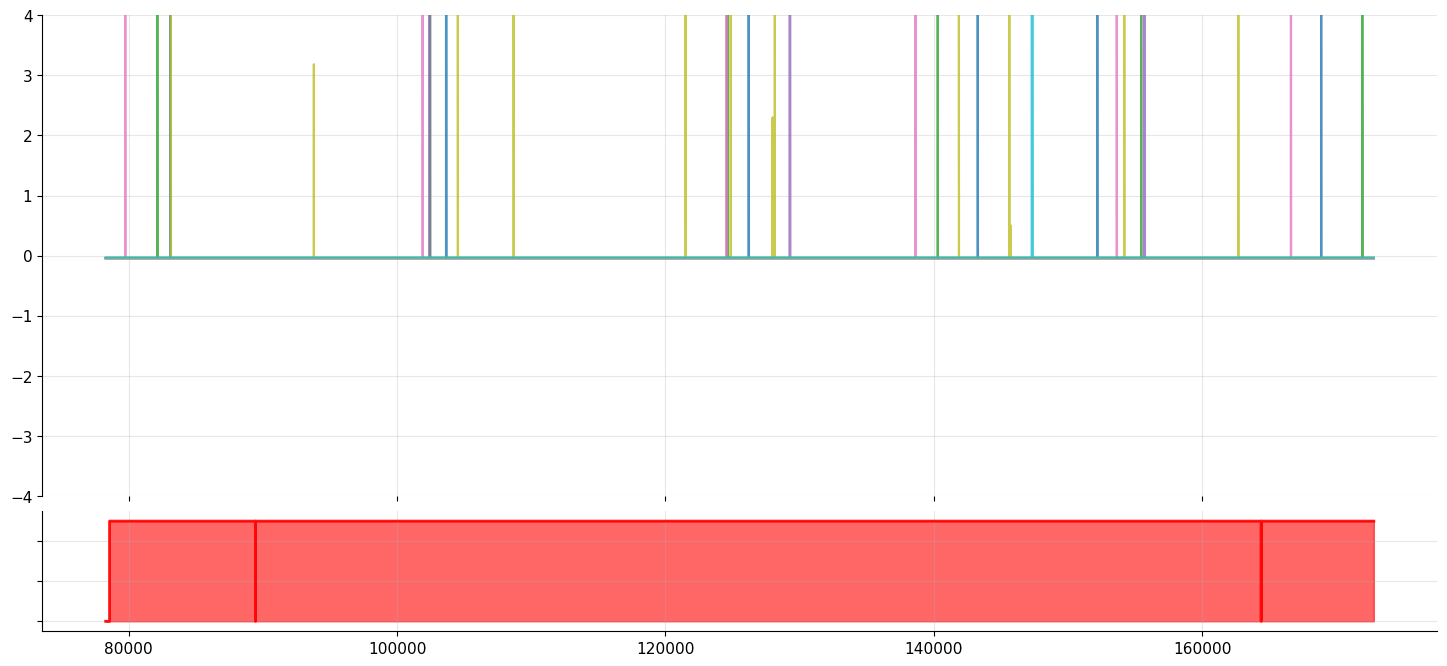

Region 1: 축 유지, score 숫자 제거 완료


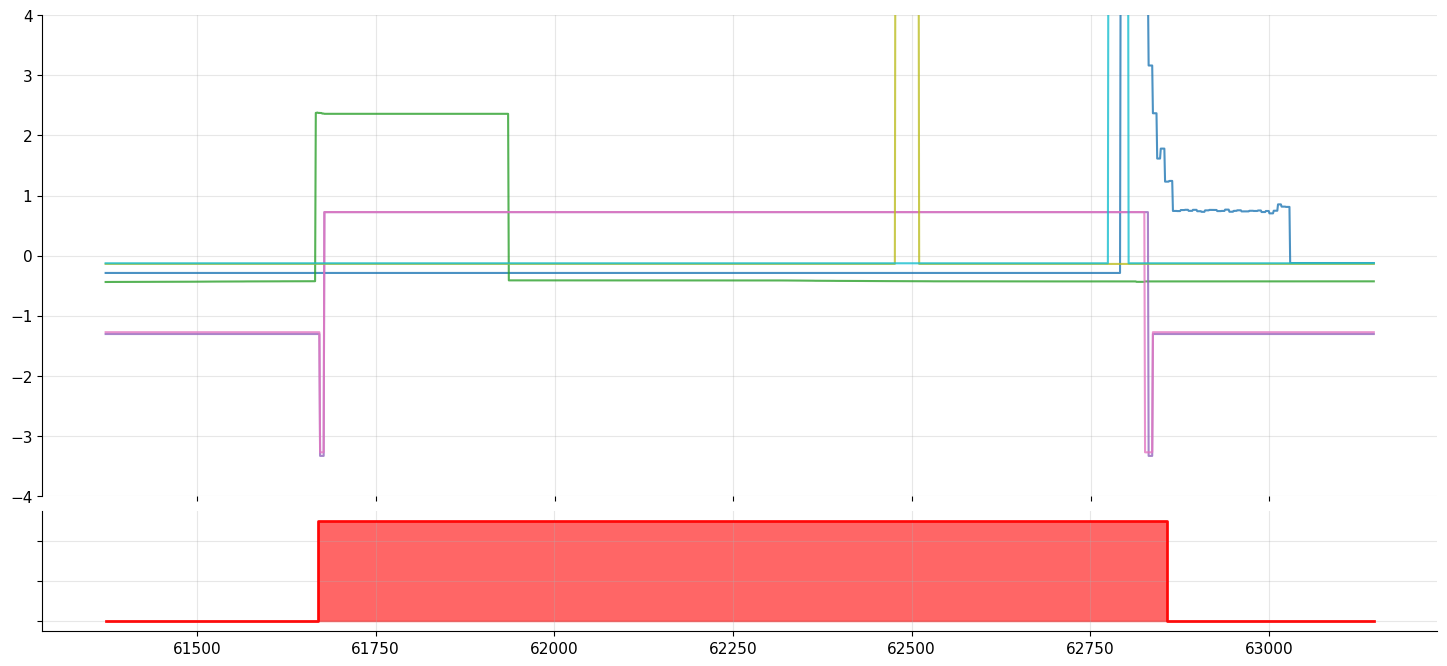

Region 2: 축 유지, score 숫자 제거 완료


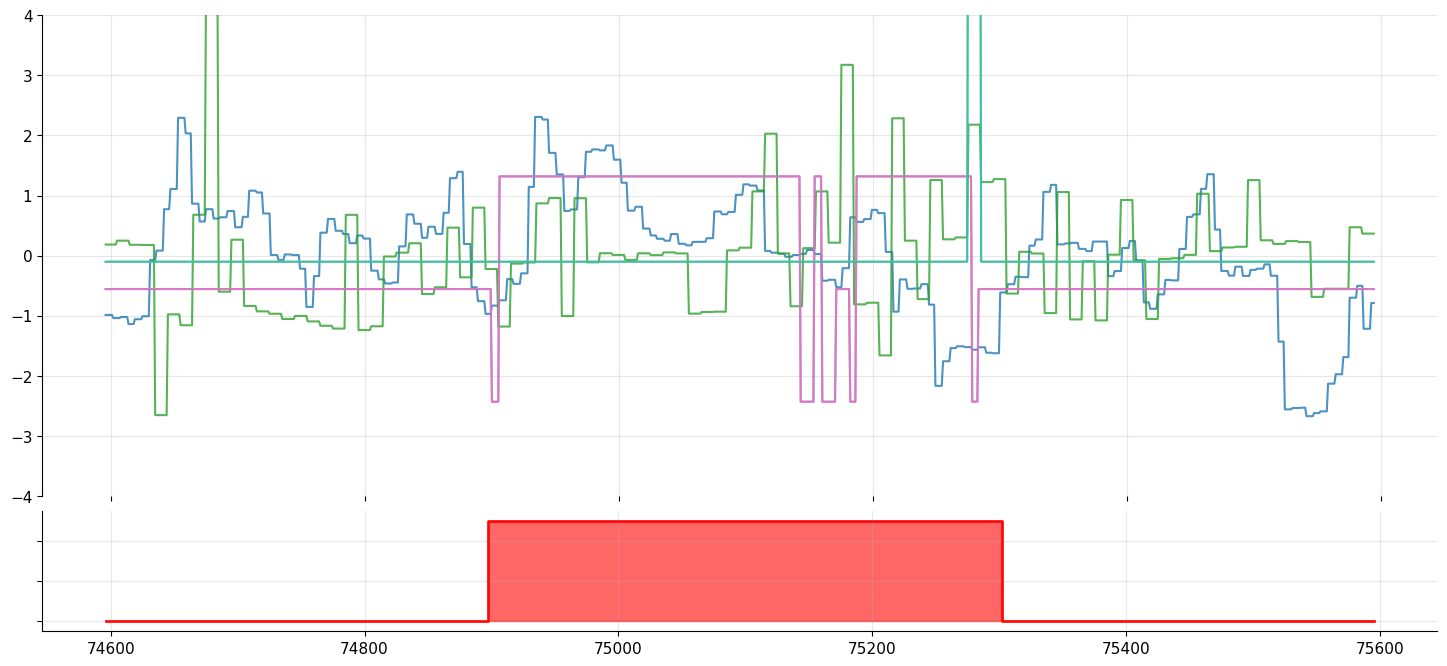

Region 3: 축 유지, score 숫자 제거 완료

✨ 수정 완료!
생성된 파일:
- axis_kept_region_1.png
- axis_kept_region_2.png
- axis_kept_region_3.png


In [25]:
import matplotlib.pyplot as plt
import numpy as np
from sklearn.preprocessing import StandardScaler

print("=== 축 유지, Anomaly Score 숫자만 제거 ===")

def plot_axis_with_no_score_labels():
    """축은 유지하고 anomaly score 축의 숫자만 제거"""
    
    # 테스트 데이터 재로딩
    with open('/Users/jieun/Desktop/GIT/Research/datasets/WADI/WADI.pk', 'rb') as file:
        wadi_data = pk.load(file)
    x_tst = wadi_data['x_tst']
    
    # 대표 구간 선택
    representative_regions = select_representative_regions(predictions, all_anomaly_scores, n_regions=3)
    
    if len(representative_regions) == 0:
        print("표시할 이상 구간이 없습니다.")
        return
    
    # GridSpec을 사용하여 높이 비율 조정 (4:1)
    from matplotlib.gridspec import GridSpec
    
    for idx, (start_window, end_window, avg_score) in enumerate(representative_regions):
        # 각 구간마다 별도의 figure 생성
        fig = plt.figure(figsize=(18, 8))
        gs = GridSpec(2, 1, height_ratios=[4, 1], hspace=0.05)
        
        sensor_ax = fig.add_subplot(gs[0])  # 상단 (큰 영역)
        score_ax = fig.add_subplot(gs[1])   # 하단 (작은 영역)
        
        # 원본 데이터 인덱스 계산
        window_size = 8
        stride = 8
        context_size = 300
        
        original_start = start_window * stride
        original_end = (end_window + 1) * stride + window_size - 1
        
        # 확장된 구간
        plot_start = max(0, original_start - context_size)
        plot_end = min(len(x_tst) - 1, original_end + context_size)
        
        # === 상단: 센서 데이터 ===
        segment_data = x_tst[plot_start:plot_end]
        time_indices = np.arange(plot_start, plot_end)
        
        # Z-Score 정규화
        segment_data_original = segment_data * train_std + train_mean
        scaler = StandardScaler()
        segment_data_normalized = scaler.fit_transform(segment_data_original)
        
        # 변동성 기반 센서 선택 (6개)
        anomaly_start_idx = max(0, original_start - plot_start)
        anomaly_end_idx = min(len(segment_data), original_end - plot_start)
        
        if anomaly_end_idx > anomaly_start_idx:
            anomaly_data = segment_data_normalized[anomaly_start_idx:anomaly_end_idx]
            normal_data = np.concatenate([
                segment_data_normalized[:anomaly_start_idx],
                segment_data_normalized[anomaly_end_idx:]
            ])
            
            if len(normal_data) > 0 and len(anomaly_data) > 0:
                anomaly_var = np.var(anomaly_data, axis=0)
                normal_var = np.var(normal_data, axis=0)
                variance_ratio = anomaly_var / (normal_var + 1e-8)
                top_sensors = np.argsort(variance_ratio)[-6:]
            else:
                overall_var = np.var(segment_data_normalized, axis=0)
                top_sensors = np.argsort(overall_var)[-6:]
        else:
            top_sensors = np.arange(min(6, segment_data_normalized.shape[1]))
        
        # 센서 데이터 플롯
        colors = plt.cm.tab10(np.linspace(0, 1, len(top_sensors)))
        
        for i, sensor_idx in enumerate(top_sensors):
            sensor_ax.plot(time_indices, segment_data_normalized[:, sensor_idx], 
                          color=colors[i], linewidth=1.5, alpha=0.8)
        
        # === 하단: Binary Anomaly Score ===
        # 해당 구간의 anomaly score 추출
        score_start_window = max(0, start_window - context_size//stride)
        score_end_window = min(len(all_anomaly_scores), end_window + context_size//stride)
        score_segment = all_anomaly_scores[score_start_window:score_end_window]
        
        # Binary로 변환: 임계값보다 높으면 5, 낮으면 0
        binary_scores = np.where(score_segment > best_threshold, 5, 0)
        
        # score를 시간축에 매핑
        score_time_indices = np.linspace(plot_start, plot_end, len(binary_scores))
        
        # Binary anomaly score 플롯
        score_ax.step(score_time_indices, binary_scores, 
                     where='mid', color='red', linewidth=2, alpha=0.9)
        score_ax.fill_between(score_time_indices, 0, binary_scores, 
                             step='mid', color='red', alpha=0.6)
        
        # === 스타일링 ===
        # 센서 축 (상단) - 축과 숫자 모두 유지
        sensor_ax.set_ylim(-4, 4)
        sensor_ax.grid(True, alpha=0.3)
        sensor_ax.spines['top'].set_visible(False)
        sensor_ax.spines['right'].set_visible(False)
        sensor_ax.spines['bottom'].set_visible(False)  # 하단 경계선만 제거
        
        # Score 축 (하단) - 축은 유지, 숫자만 제거
        score_ax.set_ylim(-0.5, 5.5)
        score_ax.grid(True, alpha=0.3)
        score_ax.spines['top'].set_visible(False)
        score_ax.spines['right'].set_visible(False)
        
        # 텍스트 및 라벨 제거
        sensor_ax.set_xlabel('')
        sensor_ax.set_ylabel('')
        sensor_ax.set_title('')
        sensor_ax.set_xticklabels([])  # x축 숫자만 제거
        
        score_ax.set_xlabel('')
        score_ax.set_ylabel('')
        score_ax.set_title('')
        score_ax.set_yticklabels([])  # ★ anomaly score 축의 y값만 제거
        # score_ax의 x축 숫자는 유지 (하단이므로)
        
        plt.savefig(f'axis_kept_region_{idx+1}.png', dpi=300, bbox_inches='tight')
        plt.show()
        
        print(f"Region {idx+1}: 축 유지, score 숫자 제거 완료")
    
    del wadi_data, x_tst

def select_representative_regions(predictions, scores, n_regions=3, min_length=15):
    """대표적인 이상 구간 선택"""
    anomaly_indices = np.where(predictions == 1)[0]
    
    if len(anomaly_indices) == 0:
        return []
    
    regions = []
    start = anomaly_indices[0]
    
    for i in range(1, len(anomaly_indices)):
        if anomaly_indices[i] - anomaly_indices[i-1] > 5:
            end = anomaly_indices[i-1]
            if end - start >= min_length:
                avg_score = np.mean(scores[start:end+1])
                regions.append((start, end, avg_score))
            start = anomaly_indices[i]
    
    end = anomaly_indices[-1]
    if end - start >= min_length:
        avg_score = np.mean(scores[start:end+1])
        regions.append((start, end, avg_score))
    
    regions.sort(key=lambda x: x[2], reverse=True)
    return regions[:n_regions]

# 실행
print("축 유지, anomaly score 숫자만 제거...")
plot_axis_with_no_score_labels()

print("\n✨ 수정 완료!")
print("생성된 파일:")
print("- axis_kept_region_1.png")
print("- axis_kept_region_2.png") 
print("- axis_kept_region_3.png")

=== 긴 구간, 정상+비정상 혼합, 채우기 제거 ===
긴 구간, 정상+비정상 혼합 분석...


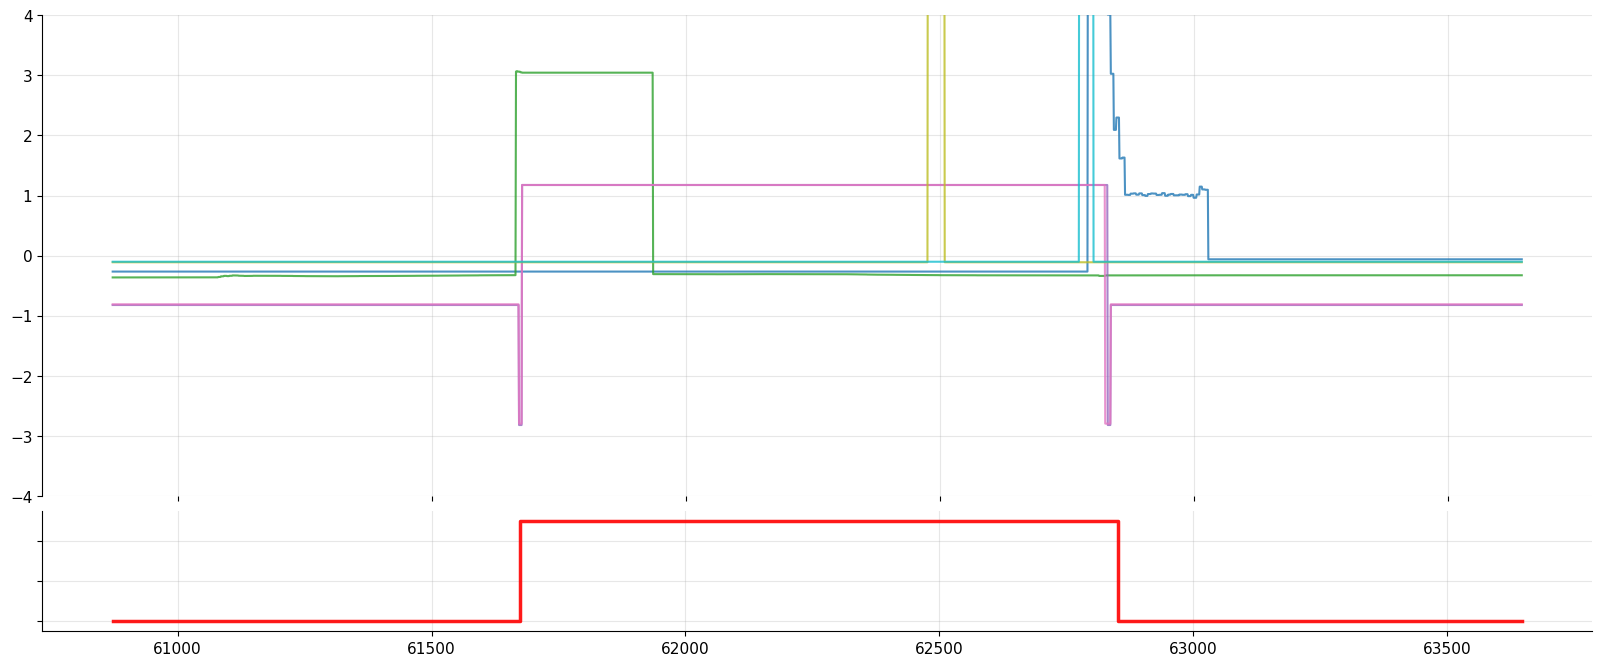

Region 1:
  - 전체 구간: 60872-63647 (길이: 2775)
  - 정상 구간: 199/345 (57.7%)
  - 이상 구간: 146/345 (42.3%)

✨ 확장된 혼합 구간 분석 완료!
생성된 파일:
- extended_mixed_region_1.png
- extended_mixed_region_2.png
- extended_mixed_region_3.png


In [26]:
import matplotlib.pyplot as plt
import numpy as np
from sklearn.preprocessing import StandardScaler

print("=== 긴 구간, 정상+비정상 혼합, 채우기 제거 ===")

def plot_extended_mixed_anomaly():
    """더 긴 구간으로 정상과 비정상이 섞인 그래프, 채우기 없음"""
    
    # 테스트 데이터 재로딩
    with open('/Users/jieun/Desktop/GIT/Research/datasets/WADI/WADI.pk', 'rb') as file:
        wadi_data = pk.load(file)
    x_tst = wadi_data['x_tst']
    
    # 대표 구간 선택 (더 긴 구간으로)
    representative_regions = select_extended_mixed_regions(predictions, all_anomaly_scores, n_regions=3)
    
    if len(representative_regions) == 0:
        print("표시할 이상 구간이 없습니다.")
        return
    
    # GridSpec을 사용하여 높이 비율 조정 (4:1)
    from matplotlib.gridspec import GridSpec
    
    for idx, (start_window, end_window, avg_score) in enumerate(representative_regions):
        # 각 구간마다 별도의 figure 생성
        fig = plt.figure(figsize=(20, 8))  # 더 넓게
        gs = GridSpec(2, 1, height_ratios=[4, 1], hspace=0.05)
        
        sensor_ax = fig.add_subplot(gs[0])  # 상단 (큰 영역)
        score_ax = fig.add_subplot(gs[1])   # 하단 (작은 영역)
        
        # 원본 데이터 인덱스 계산 (훨씬 더 긴 구간)
        window_size = 8
        stride = 8
        context_size = 800  # 300 -> 800으로 대폭 증가
        
        original_start = start_window * stride
        original_end = (end_window + 1) * stride + window_size - 1
        
        # 확장된 구간 (정상과 비정상이 충분히 섞이도록)
        plot_start = max(0, original_start - context_size)
        plot_end = min(len(x_tst) - 1, original_end + context_size)
        
        # === 상단: 센서 데이터 ===
        segment_data = x_tst[plot_start:plot_end]
        time_indices = np.arange(plot_start, plot_end)
        
        # Z-Score 정규화
        segment_data_original = segment_data * train_std + train_mean
        scaler = StandardScaler()
        segment_data_normalized = scaler.fit_transform(segment_data_original)
        
        # 변동성 기반 센서 선택 (6개)
        anomaly_start_idx = max(0, original_start - plot_start)
        anomaly_end_idx = min(len(segment_data), original_end - plot_start)
        
        if anomaly_end_idx > anomaly_start_idx:
            anomaly_data = segment_data_normalized[anomaly_start_idx:anomaly_end_idx]
            normal_data = np.concatenate([
                segment_data_normalized[:anomaly_start_idx],
                segment_data_normalized[anomaly_end_idx:]
            ])
            
            if len(normal_data) > 0 and len(anomaly_data) > 0:
                anomaly_var = np.var(anomaly_data, axis=0)
                normal_var = np.var(normal_data, axis=0)
                variance_ratio = anomaly_var / (normal_var + 1e-8)
                top_sensors = np.argsort(variance_ratio)[-6:]
            else:
                overall_var = np.var(segment_data_normalized, axis=0)
                top_sensors = np.argsort(overall_var)[-6:]
        else:
            top_sensors = np.arange(min(6, segment_data_normalized.shape[1]))
        
        # 센서 데이터 플롯
        colors = plt.cm.tab10(np.linspace(0, 1, len(top_sensors)))
        
        for i, sensor_idx in enumerate(top_sensors):
            sensor_ax.plot(time_indices, segment_data_normalized[:, sensor_idx], 
                          color=colors[i], linewidth=1.5, alpha=0.8)
        
        # === 하단: Binary Anomaly Score (채우기 없음) ===
        # 해당 구간의 anomaly score 추출 (더 긴 범위)
        score_start_window = max(0, start_window - context_size//stride)
        score_end_window = min(len(all_anomaly_scores), end_window + context_size//stride)
        score_segment = all_anomaly_scores[score_start_window:score_end_window]
        
        # Binary로 변환: 임계값보다 높으면 5, 낮으면 0
        binary_scores = np.where(score_segment > best_threshold, 5, 0)
        
        # score를 시간축에 매핑
        score_time_indices = np.linspace(plot_start, plot_end, len(binary_scores))
        
        # Binary anomaly score 플롯 (선만, 채우기 없음)
        score_ax.step(score_time_indices, binary_scores, 
                     where='mid', color='red', linewidth=2.5, alpha=0.9)
        # ❌ fill_between 제거 (채우기 없음)
        
        # === 스타일링 ===
        # 센서 축 (상단)
        sensor_ax.set_ylim(-4, 4)
        sensor_ax.grid(True, alpha=0.3)
        sensor_ax.spines['top'].set_visible(False)
        sensor_ax.spines['right'].set_visible(False)
        sensor_ax.spines['bottom'].set_visible(False)
        
        # Score 축 (하단)
        score_ax.set_ylim(-0.5, 5.5)
        score_ax.grid(True, alpha=0.3)
        score_ax.spines['top'].set_visible(False)
        score_ax.spines['right'].set_visible(False)
        
        # 텍스트 및 라벨 제거
        sensor_ax.set_xlabel('')
        sensor_ax.set_ylabel('')
        sensor_ax.set_title('')
        sensor_ax.set_xticklabels([])
        
        score_ax.set_xlabel('')
        score_ax.set_ylabel('')
        score_ax.set_title('')
        score_ax.set_yticklabels([])  # anomaly score 축의 y값만 제거
        
        plt.savefig(f'extended_mixed_region_{idx+1}.png', dpi=300, bbox_inches='tight')
        plt.show()
        
        # 정상/비정상 구간 비율 출력
        normal_count = np.sum(binary_scores == 0)
        anomaly_count = np.sum(binary_scores == 5)
        total_count = len(binary_scores)
        
        print(f"Region {idx+1}:")
        print(f"  - 전체 구간: {plot_start}-{plot_end} (길이: {plot_end-plot_start})")
        print(f"  - 정상 구간: {normal_count}/{total_count} ({normal_count/total_count*100:.1f}%)")
        print(f"  - 이상 구간: {anomaly_count}/{total_count} ({anomaly_count/total_count*100:.1f}%)")
    
    del wadi_data, x_tst

def select_extended_mixed_regions(predictions, scores, n_regions=3, min_length=20):
    """정상과 비정상이 잘 섞인 긴 구간 선택"""
    anomaly_indices = np.where(predictions == 1)[0]
    
    if len(anomaly_indices) == 0:
        return []
    
    # 더 큰 구간으로 그룹화
    regions = []
    start = anomaly_indices[0]
    
    for i in range(1, len(anomaly_indices)):
        if anomaly_indices[i] - anomaly_indices[i-1] > 10:  # 더 큰 gap으로 구분
            end = anomaly_indices[i-1]
            if end - start >= min_length:
                avg_score = np.mean(scores[start:end+1])
                
                # 해당 구간 주변에 정상 구간이 충분히 있는지 확인
                extended_start = max(0, start - 100)
                extended_end = min(len(predictions), end + 100)
                extended_region = predictions[extended_start:extended_end]
                
                # 정상과 비정상이 적절히 섞인 구간인지 확인
                normal_ratio = np.sum(extended_region == 0) / len(extended_region)
                if 0.3 <= normal_ratio <= 0.8:  # 30-80% 정상 구간
                    regions.append((start, end, avg_score))
            start = anomaly_indices[i]
    
    # 마지막 구간
    end = anomaly_indices[-1]
    if end - start >= min_length:
        avg_score = np.mean(scores[start:end+1])
        extended_start = max(0, start - 100)
        extended_end = min(len(predictions), end + 100)
        extended_region = predictions[extended_start:extended_end]
        normal_ratio = np.sum(extended_region == 0) / len(extended_region)
        if 0.3 <= normal_ratio <= 0.8:
            regions.append((start, end, avg_score))
    
    # 점수와 혼합도를 고려하여 정렬
    regions.sort(key=lambda x: x[2], reverse=True)
    return regions[:n_regions]

# 실행
print("긴 구간, 정상+비정상 혼합 분석...")
plot_extended_mixed_anomaly()

print("\n✨ 확장된 혼합 구간 분석 완료!")
print("생성된 파일:")
print("- extended_mixed_region_1.png")
print("- extended_mixed_region_2.png") 
print("- extended_mixed_region_3.png")

In [ ]:
# 이상 탐지가 어려운 데이터를 위한 개선된 학습 설정

def get_adaptive_loss_weights(epoch, data_difficulty="hard"):
    """데이터 난이도에 따른 적응적 손실 가중치"""
    
    if data_difficulty == "hard":  # trimSyn 같은 어려운 데이터
        # 더 긴 warm-up, 더 강한 정규화
        beta_schedule = min(0.5, epoch / 40.0)  # KL 가중치를 더 천천히, 더 작게
        
        # Reconstruction에 더 집중 (초기)
        recon_weight = 1.0
        
        # Gradient smoothness를 점진적으로 증가
        grad_weight = min(0.1, epoch / 100.0)  # 더 천천히 증가
        
        # Drift loss (continuous anomaly detection)
        drift_weight = min(0.2, epoch / 50.0)  # 천천히 증가
        
    elif data_difficulty == "medium":  # 중간 난이도
        beta_schedule = min(0.8, epoch / 25.0)
        recon_weight = 1.0
        grad_weight = min(0.05, epoch / 50.0)
        drift_weight = min(0.15, epoch / 30.0)
        
    else:  # "easy" - 쉬운 데이터
        beta_schedule = min(1.0, epoch / 20.0)
        recon_weight = 1.0
        grad_weight = 0.01
        drift_weight = 0.1
    
    return {
        'recon_weight': recon_weight,
        'kl_weight': beta_schedule,
        'grad_weight': grad_weight,
        'drift_weight': drift_weight
    }

def improved_training_loop_for_hard_data(model, train_loader, num_epochs=100, data_difficulty="hard"):
    """어려운 데이터를 위한 개선된 학습 루프"""
    
    device = next(model.parameters()).device
    
    # 더 보수적인 학습률과 정규화
    if data_difficulty == "hard":
        optimizer = torch.optim.AdamW(
            model.parameters(), 
            lr=1e-4,              # 더 작은 학습률
            weight_decay=5e-4,    # 더 강한 weight decay
            betas=(0.9, 0.999)
        )
        # 더 긴 주기의 스케줄러
        scheduler = torch.optim.lr_scheduler.CosineAnnealingWarmRestarts(
            optimizer, T_0=20, T_mult=2, eta_min=1e-6
        )
    else:
        optimizer = torch.optim.AdamW(
            model.parameters(), 
            lr=5e-4, 
            weight_decay=1e-4, 
            betas=(0.9, 0.999)
        )
        scheduler = torch.optim.lr_scheduler.CosineAnnealingWarmRestarts(
            optimizer, T_0=10, T_mult=2
        )
    
    model.train()
    print(f"어려운 데이터 학습 시작 (난이도: {data_difficulty}, epochs: {num_epochs})")
    
    # Early stopping 조건 완화
    best_loss = float('inf')
    patience = 20 if data_difficulty == "hard" else 10  # 더 긴 patience
    patience_counter = 0
    
    loss_history = []
    
    for epoch in range(num_epochs):
        total_loss = 0
        recon_loss_sum = 0
        kl_loss_sum = 0
        grad_loss_sum = 0
        drift_loss_sum = 0
        n_batches = 0
        
        # 에포크별 적응적 가중치
        weights = get_adaptive_loss_weights(epoch, data_difficulty)
        
        for batch_data in train_loader:
            if isinstance(batch_data, (list, tuple)):
                if len(batch_data) == 3:
                    batch_x, batch_times, batch_mask = batch_data
                    batch_x = batch_x.to(device)
                    batch_times = batch_times.to(device)
                    batch_mask = batch_mask.to(device)
                else:
                    batch_x, batch_times = batch_data
                    batch_x = batch_x.to(device)
                    batch_times = batch_times.to(device)
                    batch_mask = None
            else:
                batch_x = batch_data.to(device)
                batch_times = torch.linspace(0, 1, batch_x.size(1)).to(device)
                batch_mask = None
            
            optimizer.zero_grad()
            
            try:
                outputs = model(batch_x, batch_times, batch_mask)
                losses = outputs['losses']
                
                # 적응적 가중치 적용
                total_batch_loss = (
                    weights['recon_weight'] * losses['recon_loss'] + 
                    weights['kl_weight'] * losses['kl_loss'] + 
                    weights['grad_weight'] * losses['grad_smoothness']
                )
                
                # Drift loss가 있다면 추가
                if 'drift_loss' in losses:
                    total_batch_loss += weights['drift_weight'] * losses['drift_loss']
                    drift_loss_sum += losses['drift_loss'].item()
                
                total_batch_loss.backward()
                
                # 더 강한 gradient clipping for hard data
                max_norm = 0.1 if data_difficulty == "hard" else 0.5
                torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=max_norm)
                
                optimizer.step()
                
                total_loss += total_batch_loss.item()
                recon_loss_sum += losses['recon_loss'].item()
                kl_loss_sum += losses['kl_loss'].item()
                grad_loss_sum += losses['grad_smoothness'].item()
                n_batches += 1
                        
            except RuntimeError as e:
                print(f"배치 처리 오류 (계속 진행): {e}")
                continue
        
        scheduler.step()
        
        avg_loss = total_loss / max(n_batches, 1)
        loss_history.append(avg_loss)
        
        # Early stopping 조건 (더 관대하게)
        if avg_loss < best_loss * 0.995:  # 0.5% 이상 개선 시에만 업데이트
            best_loss = avg_loss
            patience_counter = 0
        else:
            patience_counter += 1
            
        if patience_counter >= patience and epoch > 30:  # 최소 30 에포크는 학습
            print(f"Early stopping at epoch {epoch}")
            break
        
        # 더 자주 로그 출력 (어려운 데이터의 경우)
        log_interval = 5 if data_difficulty == "hard" else max(1, num_epochs // 10)
        if epoch % log_interval == 0:
            print(f"Epoch {epoch:3d}/{num_epochs}: Loss = {avg_loss:.6f} "
                  f"(R: {recon_loss_sum/n_batches:.4f}, "
                  f"KL: {kl_loss_sum/n_batches:.4f}, "
                  f"G: {grad_loss_sum/n_batches:.4f}"
                  f"{f', D: {drift_loss_sum/n_batches:.4f}' if drift_loss_sum > 0 else ''}) "
                  f"[W: R={weights['recon_weight']:.2f}, KL={weights['kl_weight']:.2f}]")
    
    print("Training completed.")
    print(f"최종 손실: {avg_loss:.6f}")
    print(f"최고 성능 손실: {best_loss:.6f}")
    
    return loss_history

# 사용 예시:
print("어려운 데이터를 위한 학습 설정 완료!")
print("사용법:")
print("loss_history = improved_training_loop_for_hard_data(model, train_loader, num_epochs=100, data_difficulty='hard')")
